# Paris Airbnb: prices, future review activity and revenue scenarios

**Jupyter research notebook · Updated 11 November 2026 · English**

This notebook contains the implementation, model fitting and outputs in its cells. It uses four Paris listing snapshots, four review snapshots and the September calendar, with official transport locations for an external-data comparison. No project Python module is imported: the processing functions are included below.

The study distinguishes quoted prices, observed reviews and assumed earnings. Actual host revenue is unavailable. Nothing in this notebook treats calendar unavailability as confirmed bookings.

**How to run:** clone this repository or extract its ZIP, open this notebook from the repository root (beside the `data` folder), and choose **Restart Kernel and Run All**. The default reuses the supplied cleaned analytical tables, then refits every model. Set `REBUILD_INPUTS = True` to also reconstruct those tables from the raw source files. Missing public raw files can be downloaded when that option is enabled. The full raw inputs use several GB of disk space. The original user-supplied files are never overwritten.

Dependencies: Python 3, numpy, pandas, scikit-learn, matplotlib, joblib and IPython; see `requirements.txt`. Jupyter Notebook or JupyterLab is the interface used to open this file.


In [1]:
"""Reproducible Paris Airbnb analysis. Run from this directory; see README.md."""
from __future__ import annotations

import argparse
import calendar
import hashlib
import json
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/airbnb_project_mpl")
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import BallTree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

ROOT = Path.cwd().resolve()
DEFAULT_DATA = ROOT / "data/raw"
SEED = 42
EARTH_KM = 6371.0088
INTERNAL = ["accommodates", "bedrooms", "beds", "bathrooms_n", "minimum_nights",
            "amenity_count", "wifi", "kitchen", "washer", "air_conditioning", "elevator",
            "quote_stay_nights", "quote_month_sin", "quote_month_cos", "quote_lead_days"]
LOCATION = ["latitude", "longitude"]
TRANSIT = ["nearest_metro_km", "metro_stations_500m", "metro_stations_1000m", "nearest_rer_km"]
PRICE_SETS = {"internal": (INTERNAL, ["property_type"]),
              "location": (INTERNAL + LOCATION, ["property_type", "neighbourhood_cleansed"]),
              "transit": (INTERNAL + LOCATION + TRANSIT, ["property_type", "neighbourhood_cleansed"])}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.facecolor": "white"})
COLORS = ["#9aa6b3", "#557893", "#0b6e75", "#cf8c36"]



from IPython.display import display, Image
import gzip, shutil, urllib.request
REBUILD_INPUTS = False
DOWNLOAD_MISSING = True
if not DEFAULT_DATA.exists():
    DEFAULT_DATA = ROOT / 'data/raw'
for folder in ['data', 'data/insideairbnb', 'results', 'figures', 'models']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print('Project directory:', ROOT)
print('Rebuild raw inputs:', REBUILD_INPUTS)
print('pandas:', pd.__version__, 'scikit-learn:', sklearn.__version__)


Project directory: airbnb_project
Rebuild raw inputs: False
pandas: 3.0.0 scikit-learn: 1.9.1


In [2]:
def dump(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding="utf-8")


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

## 1. Source files and download controls

The public Paris snapshots are dated 13 December 2025, 21 March 2026, 16 June 2026 and 16 September 2026. Each listing also has its actual capture date; that date, rather than the batch label, determines whether an input precedes a forecast.

The official station file was acquired on 10 November 2026. The original September listings and reviews are reused if available at the configured local path. On a different computer, change `DEFAULT_DATA` above or enable rebuilding to download the public copies.


In [3]:
SOURCE_ROOT = 'https://data.insideairbnb.com/france/ile-de-france/paris/'
DATES = ['2025-12-13', '2026-03-21', '2026-06-16', '2026-09-16']

def download_if_missing(url, destination):
    destination = Path(destination)
    if destination.exists():
        return
    if not DOWNLOAD_MISSING:
        raise FileNotFoundError(f'Missing source: {destination}. Enable DOWNLOAD_MISSING or supply the file.')
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + '.part')
    print('Downloading', url, flush=True)
    with urllib.request.urlopen(url, timeout=180) as response, temporary.open('wb') as out:
        shutil.copyfileobj(response, out, length=8*1024*1024)
    temporary.replace(destination)

if REBUILD_INPUTS:
    DEFAULT_DATA.mkdir(parents=True, exist_ok=True)
    for kind in ['listings', 'reviews']:
        dest = DEFAULT_DATA / f'{kind}.csv'
        if not dest.exists():
            compressed = ROOT / 'data/insideairbnb' / f'{kind}_{DATES[-1]}.csv.gz'
            download_if_missing(SOURCE_ROOT + DATES[-1] + f'/data/{kind}.csv.gz', compressed)
            temporary = dest.with_name(dest.name + '.part')
            with gzip.open(compressed, 'rb') as src, temporary.open('wb') as out:
                shutil.copyfileobj(src, out)
            temporary.replace(dest)
    for date in DATES[:-1]:
        for kind in ['listings', 'reviews']:
            download_if_missing(SOURCE_ROOT + date + f'/data/{kind}.csv.gz', ROOT / 'data/insideairbnb' / f'{kind}_{date}.csv.gz')
    download_if_missing(SOURCE_ROOT + DATES[-1] + '/data/calendar.csv.gz', ROOT / 'data/insideairbnb/calendar_2026-09-16.csv.gz')
    download_if_missing('https://data.iledefrance-mobilites.fr/api/explore/v2.1/catalog/datasets/emplacement-des-gares-idf-data-generalisee/exports/json', ROOT / 'data/idfm_stations.json')
else:
    needed = ['data/price_features.csv.gz', 'data/review_month_panel.csv.gz', 'data/insideairbnb/temporal_review_panel.csv.gz', 'results/data_audit.json']
    missing = [p for p in needed if not (ROOT / p).exists()]
    if missing:
        raise FileNotFoundError(f'Extract the complete project package, or set REBUILD_INPUTS=True. Missing: {missing}')
print('Source configuration is ready.')


Source configuration is ready.


## 2. Clean the latest listings and reviews

Reviews are keyed by review ID and listing ID. All rows for an ID assigned to multiple listings or dates are excluded rather than allocated arbitrarily. Reviews after their own listing's capture date are also excluded. No review text, guest names or host names are read.

Prices are parsed as EUR after checking the quote's currency metadata. Missing prices are not zero. The model population is entire homes with a minimum stay of 1–29 nights and an observed quote between EUR 20 and EUR 1,000. This limits generalization to missing-price listings and the luxury tail.


In [4]:
def read_data(data_dir=DEFAULT_DATA):
    """Read only selected analytical fields; no names, comments or profile text."""
    fields = ["id", "host_id", "last_scraped", "room_type", "property_type", "price",
              "price_quote_raw", "price_quote_checkin_date", "price_quote_checkout_date",
              "latitude", "longitude", "neighbourhood_cleansed", "accommodates", "bedrooms",
              "beds", "bathrooms", "bathrooms_text", "minimum_nights", "amenities"]
    l = pd.read_csv(data_dir / "listings.csv", usecols=fields, low_memory=False)
    r = pd.read_csv(data_dir / "reviews.csv", usecols=["listing_id", "id", "date"],
                    dtype={"listing_id": "int64", "id": "int64"}, parse_dates=["date"])
    assert l.id.is_unique, "Duplicate listing IDs require resolution."
    assert r.date.notna().all(), "Missing review dates require resolution."
    audit = {"listing_rows": len(l), "listing_fields_in_source": len(pd.read_csv(data_dir / "listings.csv", nrows=0).columns),
             "review_rows_raw": len(r), "snapshot_start": l.last_scraped.min(),
             "snapshot_end": l.last_scraped.max(), "review_date_min": str(r.date.min().date()),
             "review_date_max": str(r.date.max().date()), "review_orphan_rows": int((~r.listing_id.isin(l.id)).sum())}
    # The same review ID can occur for several listings. Do not assign it arbitrarily.
    conflicts = r.groupby("id").agg(listings=("listing_id", "nunique"), dates=("date", "nunique"))
    ambiguous = conflicts.index[(conflicts.listings > 1) | (conflicts.dates > 1)]
    audit["ambiguous_review_ids"] = len(ambiguous)
    audit["ambiguous_review_rows_excluded"] = int(r.id.isin(ambiguous).sum())
    r = r[~r.id.isin(ambiguous)].copy()
    audit["same_listing_duplicate_rows_removed"] = int(r.duplicated(["id", "listing_id", "date"]).sum())
    r = r.drop_duplicates(["id", "listing_id", "date"])
    # Match each review against its own listing's scrape date, not the latest city scrape.
    scrape = pd.to_datetime(l.set_index("id").last_scraped)
    bad = r.date > r.listing_id.map(scrape)
    audit["reviews_after_own_scrape_excluded"] = int(bad.sum())
    r = r[~bad & r.listing_id.isin(l.id)].copy()
    audit["review_rows_clean"] = len(r)
    l["price_eur"] = pd.to_numeric(l.price.str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
    def currency(s):
        try:
            return json.loads(s).get("quote", {}).get("currency")
        except (TypeError, ValueError):
            return None
    l["quote_currency"] = l.price_quote_raw.map(currency)
    audit["quote_currency_counts"] = l.quote_currency.fillna("missing").value_counts().to_dict()
    audit["price_missing_rows"] = int(l.price_eur.isna().sum())
    audit["price_missing_fraction"] = float(l.price_eur.isna().mean())
    audit["room_types"] = l.room_type.value_counts().to_dict()
    audit["quote_checkin_min"] = l.price_quote_checkin_date.min()
    audit["quote_checkin_max"] = l.price_quote_checkin_date.max()
    price_known = l.assign(price_missing=l.price_eur.isna()).groupby("room_type").agg(
        listings=("id", "size"), missing_price_fraction=("price_missing", "mean"), median_price_eur=("price_eur", "median"))
    price_known.to_csv(ROOT / "results/price_coverage.csv")
    l.drop(columns=["price_quote_raw"], inplace=True)
    return l, r, audit


def add_features(l):
    l = l.copy()
    l["bathrooms_n"] = pd.to_numeric(l.bathrooms, errors="coerce").fillna(
        pd.to_numeric(l.bathrooms_text.str.extract(r"([0-9.]+)")[0], errors="coerce"))
    def amenities(s):
        try:
            a = json.loads(s)
            return [str(x).lower() for x in a] if isinstance(a, list) else []
        except (TypeError, ValueError):
            return []
    a = l.amenities.map(amenities)
    l["amenity_count"] = a.map(len)
    for name, term in [("wifi", "wifi"), ("kitchen", "kitchen"), ("washer", "washer"),
                       ("air_conditioning", "air conditioning"), ("elevator", "elevator")]:
        l[name] = a.map(lambda xs: int(any(term in x for x in xs)))
    checkin = pd.to_datetime(l.price_quote_checkin_date, errors="coerce")
    checkout = pd.to_datetime(l.price_quote_checkout_date, errors="coerce")
    l["quote_stay_nights"] = (checkout - checkin).dt.days
    l["quote_month_sin"] = np.sin(2 * np.pi * checkin.dt.month / 12)
    l["quote_month_cos"] = np.cos(2 * np.pi * checkin.dt.month / 12)
    l["quote_lead_days"] = (checkin - pd.to_datetime(l.last_scraped)).dt.days
    for c in INTERNAL:
        l[c] = pd.to_numeric(l[c], errors="coerce")
    for c in ["property_type", "neighbourhood_cleansed"]:
        l[c] = l[c].fillna("Unknown").astype(str)
    return l


def add_transit(l):
    stations = pd.DataFrame(json.loads((ROOT / "data/idfm_stations.json").read_text()))
    stations["latitude"] = stations.geo_point_2d.map(lambda p: p["lat"])
    stations["longitude"] = stations.geo_point_2d.map(lambda p: p["lon"])
    # October 2026 additions postdate the Airbnb snapshot; exclude line 18 explicitly.
    excluded = stations.res_com.fillna("").str.contains(r"METRO\s*18", regex=True)
    stations = stations[~excluded].copy()
    stations = stations.drop_duplicates("codeunique")
    points = np.radians(l[["latitude", "longitude"]].to_numpy())
    counts = {"raw_station_records": 1002, "line18_records_removed": int(excluded.sum()),
              "unique_station_records": len(stations), "retrieved": "2026-11-10",
              "source": "https://data.iledefrance-mobilites.fr/explore/dataset/emplacement-des-gares-idf-data-generalisee/"}
    for mode in ["metro", "rer"]:
        s = stations[stations[mode] == 1]
        tree = BallTree(np.radians(s[["latitude", "longitude"]].to_numpy()), metric="haversine")
        l[f"nearest_{mode}_km"] = tree.query(points, k=1)[0][:, 0] * EARTH_KM
        counts[f"{mode}_stations"] = len(s)
        if mode == "metro":
            for metres in [500, 1000]:
                l[f"metro_stations_{metres}m"] = tree.query_radius(points, r=metres / 1000 / EARTH_KM, count_only=True)
    stations[["codeunique", "nom_long", "latitude", "longitude", "metro", "rer", "res_com"]].to_csv(
        ROOT / "data/stations_used.csv", index=False)
    dump(ROOT / "results/transit_provenance.json", counts)
    return l


def price_population(l, audit):
    funnel = {"all_listings": len(l)}
    d = l[l.room_type == "Entire home/apt"].copy()
    funnel["entire_homes"] = len(d)
    d = d[d.minimum_nights.between(1, 29)].copy()
    funnel["minimum_stay_1_to_29"] = len(d)
    d = d[d.price_eur.notna() & d.quote_currency.eq("EUR")].copy()
    funnel["observed_eur_price"] = len(d)
    d = d[d.price_eur.between(20, 1000)].copy()
    funnel["price_20_to_1000_eur"] = len(d)
    d = d[d.host_id.notna() & d.latitude.notna() & d.longitude.notna()].reset_index(drop=True)
    funnel["final_model_sample"] = len(d)
    audit["price_sample_funnel"] = funnel
    audit["price_sample_median_eur"] = float(d.price_eur.median())
    audit["price_sample_hosts"] = int(d.host_id.nunique())
    audit["price_sample_quote_month_counts"] = pd.to_datetime(d.price_quote_checkin_date).dt.to_period("M").astype(str).value_counts().sort_index().to_dict()
    d.groupby("neighbourhood_cleansed").agg(listings=("id", "size"), median_price_eur=("price_eur", "median"),
        median_metro_distance_m=("nearest_metro_km", lambda x: x.median() * 1000)).to_csv(ROOT / "results/neighbourhood_summary.csv")
    return d

In [5]:
if REBUILD_INPUTS:
    latest_listings, latest_reviews, audit = read_data(DEFAULT_DATA)
    audit['source_files'] = [{'path': str(DEFAULT_DATA/name), 'bytes': (DEFAULT_DATA/name).stat().st_size,
                             'sha256': sha256(DEFAULT_DATA/name)} for name in ['listings.csv', 'reviews.csv']]
    latest_listings = add_transit(add_features(latest_listings))
    price_data = price_population(latest_listings, audit)
    keep = ['id', 'host_id', 'price_eur', *list(dict.fromkeys(INTERNAL + LOCATION + TRANSIT)), 'property_type', 'neighbourhood_cleansed']
    price_data[keep].to_csv(ROOT/'data/price_features.csv.gz', index=False, compression='gzip')
else:
    audit = json.loads((ROOT/'results/data_audit.json').read_text())
    price_data = pd.read_csv(ROOT/'data/price_features.csv.gz')
display(pd.DataFrame(audit['price_sample_funnel'].items(), columns=['Selection step', 'Listings']))
print('Missing prices in original listings:', f"{audit['price_missing_fraction']:.1%}")
print('Ambiguous review rows excluded:', f"{audit['ambiguous_review_rows_excluded']:,}")
display(price_data.head())


,Selection step,Listings
0,all_listings,77149
1,entire_homes,68333
2,minimum_stay_1_to_29,53472
3,observed_eur_price,32415
4,price_20_to_1000_eur,31044
5,final_model_sample,31044


Missing prices in original listings: 43.6%
Ambiguous review rows excluded: 42,347


,id,host_id,price_eur,accommodates,bedrooms,beds,bathrooms_n,minimum_nights,amenity_count,wifi,...,quote_month_cos,quote_lead_days,latitude,longitude,nearest_metro_km,metro_stations_500m,metro_stations_1000m,nearest_rer_km,property_type,neighbourhood_cleansed
0,3109,3631,272.50,2,1.0,1.0,1.0,2.0,15,1,...,-1.836970e-16,2.0,48.831910,2.318700,0.257587,2,5,1.069454,Entire rental unit,Observatoire
1,7397,2626,149.40,4,2.0,1.0,1.0,10.0,25,1,...,8.660254e-01,56.0,48.859090,2.353150,0.218486,3,14,0.542108,Entire rental unit,Hôtel-de-Ville
2,9952,33534,177.75,2,1.0,1.0,1.0,4.0,37,1,...,8.660254e-01,69.0,48.863730,2.370930,0.259033,6,15,1.762396,Entire rental unit,Popincourt
3,11265,41718,222.86,2,1.0,1.0,1.0,7.0,42,1,...,8.660254e-01,62.0,48.884940,2.339970,0.152639,3,10,1.276882,Entire rental unit,Buttes-Montmartre
4,11798,44444,153.50,2,1.0,1.0,1.0,4.0,49,1,...,-1.836970e-16,7.0,48.825241,2.367469,0.214871,2,8,0.851099,Entire loft,Gobelins


## 3. Price features, model and holdout design

The internal model uses physical attributes, amenities and quote context. Location adds coordinates and arrondissement. Transit adds distances and station densities. IDs, current review scores, availability and estimated revenue are excluded.

The estimator predicts log quoted price. Exponentiating yields a price benchmark, not an unbiased expected transaction price or an optimal rate. All encoders are fitted on the training split. One evaluation holds out hosts; the other holds out approximately 1 km cells and removes overlapping hosts from training. The bootstrap intervals are conditional on a fixed fitted model and do not capture all spatial dependence.


In [6]:
def price_model(name):
    nums, cats = PRICE_SETS[name]
    prep = ColumnTransformer([("numeric", "passthrough", nums),
        ("categorical", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                                        encoded_missing_value=np.nan), cats)])
    model = HistGradientBoostingRegressor(max_iter=220, learning_rate=.06, max_leaf_nodes=20,
        l2_regularization=4, min_samples_leaf=30, early_stopping=False, random_state=SEED,
        categorical_features=[False] * len(nums) + [True] * len(cats))
    return Pipeline([("prepare", prep), ("model", model)])


def price_metrics(y, pred):
    return {"mae_eur": float(mean_absolute_error(y, pred)),
            "rmse_eur": float(np.sqrt(mean_squared_error(y, pred))),
            "r2_eur": float(r2_score(y, pred)),
            "r2_log_price": float(r2_score(np.log(y), np.log(pred)))}


def cluster_gain(y, old, new, groups):
    # Positive = smaller MAE with the new feature set. Host-clustered paired bootstrap.
    a = pd.DataFrame({"gain": np.abs(y - old) - np.abs(y - new), "host": np.asarray(groups)})
    g = a.groupby("host").gain.agg(["sum", "size"])
    rng = np.random.default_rng(SEED)
    samples = []
    for _ in range(400):
        picked = rng.integers(0, len(g), len(g))
        b = g.iloc[picked]
        samples.append(b["sum"].sum() / b["size"].sum())
    return {"mae_reduction_eur": float(a.gain.mean()), "ci95_low": float(np.quantile(samples, .025)),
            "ci95_high": float(np.quantile(samples, .975)), "bootstrap_host_clusters": len(g)}


def fit_prices(d):
    splitter = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED)
    tr_host, te_host = next(splitter.split(d, groups=d.host_id))
    tiles = (np.floor((d.latitude - 48.80) * 111).astype(int).astype(str) + "_" +
             np.floor((d.longitude - 2.22) * 73).astype(int).astype(str))
    tr_space, te_space = next(splitter.split(d, groups=tiles))
    test_hosts = set(d.iloc[te_space].host_id)
    tr_space = np.array([i for i in tr_space if d.iloc[i].host_id not in test_hosts])
    rows, gains, splits = [], [], []
    for protocol, tr, te in [("host_holdout", tr_host, te_host), ("spatial_holdout", tr_space, te_space)]:
        assert set(d.iloc[tr].host_id).isdisjoint(set(d.iloc[te].host_id))
        if protocol == "spatial_holdout":
            assert set(tiles.iloc[tr]).isdisjoint(set(tiles.iloc[te]))
        y = d.iloc[te].price_eur.to_numpy()
        predictions = {"median_baseline": np.full(len(te), d.iloc[tr].price_eur.median())}
        for name in PRICE_SETS:
            print(f"Price model: {protocol} / {name}; train={len(tr)}, test={len(te)}", flush=True)
            model = price_model(name)
            model.fit(d.iloc[tr], np.log(d.iloc[tr].price_eur))
            predictions[name] = np.exp(model.predict(d.iloc[te]))
        for name, pred in predictions.items():
            rows.append({"protocol": protocol, "model": name, "train_rows": len(tr), "test_rows": len(te), **price_metrics(y, pred)})
        for old, new in [("internal", "location"), ("location", "transit")]:
            gains.append({"protocol": protocol, "comparison": f"{new}_vs_{old}", **cluster_gain(y, predictions[old], predictions[new], d.iloc[te].host_id)})
        p = pd.DataFrame({"listing_id": d.iloc[te].id.astype(str).to_numpy(), "actual_price_eur": y, **predictions})
        p.to_csv(ROOT / f"results/price_predictions_{protocol}.csv", index=False)
        splits.append({"protocol": protocol, "train_rows": len(tr), "test_rows": len(te),
                       "test_hosts": int(d.iloc[te].host_id.nunique()), "host_overlap": 0})
    metrics = pd.DataFrame(rows)
    metrics.to_csv(ROOT / "results/price_metrics.csv", index=False)
    pd.DataFrame(gains).to_csv(ROOT / "results/price_feature_gains.csv", index=False)
    dump(ROOT / "results/splits.json", splits)
    # Keep the location specification for the prototype. The feature comparisons are
    # exploratory; a later independent sample is required after model selection.
    chosen = "location"
    final = price_model(chosen).fit(d, np.log(d.price_eur))
    joblib.dump({"pipeline": final, "feature_set": chosen, "target": "log quoted nightly price EUR",
                 "sklearn_version": sklearn.__version__}, ROOT / "models/price_model.joblib")
    # Calibration illustration: a held-out record, scored without fitting on that record.
    candidate = d.iloc[te_host].copy()
    candidate["distance_to_median"] = abs(candidate.price_eur - d.price_eur.median())
    example = candidate.sort_values(["distance_to_median", "id"]).iloc[0]
    p = pd.read_csv(ROOT / "results/price_predictions_host_holdout.csv", dtype={"listing_id": str})
    predicted = float(p.set_index("listing_id").loc[str(example.id), chosen])
    dump(ROOT / "results/example_property.json", {"source_listing_id": str(example.id),
         "neighbourhood": example.neighbourhood_cleansed, "accommodates": int(example.accommodates),
         "observed_quote_eur": float(example.price_eur), "heldout_predicted_quote_eur": predicted,
         "model": chosen, "note": "Illustration using an existing held-out listing, not the user's property."})
    return metrics, gains, predicted, chosen

In [7]:
price_metrics_table, price_gains, example_rate, chosen_price_features = fit_prices(price_data)
display(price_metrics_table.round(3))
display(pd.DataFrame(price_gains).round(3))


Price model: host_holdout / internal; train=24821, test=6223


Price model: host_holdout / location; train=24821, test=6223


Price model: host_holdout / transit; train=24821, test=6223


Price model: spatial_holdout / internal; train=19157, test=7002


Price model: spatial_holdout / location; train=19157, test=7002


Price model: spatial_holdout / transit; train=19157, test=7002


,protocol,model,train_rows,test_rows,mae_eur,rmse_eur,r2_eur,r2_log_price
0,host_holdout,median_baseline,24821,6223,132.631,192.930,-0.091,-0.006
1,host_holdout,internal,24821,6223,90.000,134.812,0.467,0.537
2,host_holdout,location,24821,6223,77.722,119.992,0.578,0.655
3,host_holdout,transit,24821,6223,77.871,120.256,0.576,0.654
4,spatial_holdout,median_baseline,19157,7002,128.037,191.262,-0.144,-0.036
5,spatial_holdout,internal,19157,7002,84.603,127.013,0.496,0.561
6,spatial_holdout,location,19157,7002,77.861,117.707,0.567,0.635
7,spatial_holdout,transit,19157,7002,77.882,117.737,0.567,0.635


,protocol,comparison,mae_reduction_eur,ci95_low,ci95_high,bootstrap_host_clusters
0,host_holdout,location_vs_internal,12.278,10.726,13.924,4422
1,host_holdout,transit_vs_location,-0.149,-0.391,0.091,4422
2,spatial_holdout,location_vs_internal,6.741,4.839,8.648,5263
3,spatial_holdout,transit_vs_location,-0.020,-0.267,0.289,5263


## 4. Reconstruct the rolling monthly review experiment

This first review experiment reconstructs history for 12,000 listings visible in September 2026. It is conditional on survival into that snapshot. It uses only past review counts; contemporary listing attributes are absent from historical predictors.

Training: September 2024–February 2026. Validation: March–May 2026. Test: June–August 2026. A missing listing-month in this observed cohort means no recorded reviews, never zero bookings. The latest September month is excluded as incomplete.


In [8]:
def review_features(arr, t, month, first_month):
    x = pd.DataFrame({f"lag_{k}": arr[:, t-k] for k in [1, 2, 3, 6, 12]})
    for k in [3, 6, 12]:
        x[f"mean_{k}"] = arr[:, t-k:t].mean(axis=1)
    x["active_months_12"] = (arr[:, t-12:t] > 0).sum(axis=1)
    x["months_since_first_review"] = month.ordinal - first_month
    x["month_sin"] = np.sin(2 * np.pi * month.month / 12)
    x["month_cos"] = np.cos(2 * np.pi * month.month / 12)
    return x


def review_panel(l, r, audit, sample_size=12000):
    complete_end = pd.Timestamp(l.last_scraped.min()).to_period("M") - 1
    train_start = complete_end - 23
    first = r.groupby("listing_id").date.min()
    eligible = first[first < train_start.start_time].index.to_numpy()
    ids = np.sort(np.random.default_rng(SEED).choice(eligible, min(len(eligible), sample_size), replace=False))
    months = pd.period_range(train_start - 12, complete_end, freq="M")
    rr = r[r.listing_id.isin(ids)].copy()
    rr["month"] = rr.date.dt.to_period("M")
    matrix = rr.groupby(["listing_id", "month"]).size().unstack(fill_value=0).reindex(index=ids, columns=months, fill_value=0).astype(float)
    # Empty cells mean no observed reviews in this surviving cohort, never zero bookings.
    data = []
    first_month = first.reindex(ids).dt.to_period("M").astype("int64").to_numpy()
    for t in range(12, len(months)):
        x = review_features(matrix.to_numpy(), t, months[t], first_month)
        x["listing_id"] = ids
        x["month"] = str(months[t])
        x["target"] = matrix.iloc[:, t].to_numpy()
        data.append(x)
    panel = pd.concat(data, ignore_index=True)
    months_string = [str(m) for m in months[12:]]
    train_months, valid_months, test_months = months_string[:-6], months_string[-6:-3], months_string[-3:]
    audit["review_panel"] = {"population": "Current-snapshot listings with a review before training start; all room types",
        "eligible_listings": len(eligible), "sample_listings": len(ids), "rows": len(panel),
        "train_months": train_months, "validation_months": valid_months, "test_months": test_months,
        "last_complete_month": str(complete_end), "zero_target_share": float((panel.target == 0).mean())}
    panel.to_csv(ROOT / "data/review_month_panel.csv.gz", index=False, compression="gzip")
    return panel, matrix, months, first_month, train_months, valid_months, test_months

In [9]:
def restore_review_inputs(audit):
    panel = pd.read_csv(ROOT/'data/review_month_panel.csv.gz')
    cfg = audit['review_panel']
    months = pd.period_range(pd.Period(cfg['train_months'][0], freq='M')-12, cfg['last_complete_month'], freq='M')
    ids = np.sort(panel.listing_id.unique())
    matrix = pd.DataFrame(np.nan, index=ids, columns=months)
    first_month = None
    for key, group in panel.groupby('month', sort=True):
        month = pd.Period(key, freq='M')
        g = group.set_index('listing_id').reindex(ids)
        matrix[month] = g.target.to_numpy()
        if month-12 < pd.Period(cfg['train_months'][0], freq='M'):
            matrix[month-12] = g.lag_12.to_numpy()
        if first_month is None:
            first_month = month.ordinal - g.months_since_first_review.to_numpy()
    assert matrix.notna().all().all()
    return panel, matrix, months, first_month, cfg['train_months'], cfg['validation_months'], cfg['test_months']

if REBUILD_INPUTS:
    review_inputs = review_panel(latest_listings, latest_reviews, audit, sample_size=12000)
else:
    review_inputs = restore_review_inputs(audit)
display(review_inputs[0].head())
print('Rows:', len(review_inputs[0]), 'Listings:', len(review_inputs[1]))


,lag_1,lag_2,lag_3,lag_6,lag_12,mean_3,mean_6,mean_12,active_months_12,months_since_first_review,month_sin,month_cos,listing_id,month,target
0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0,83,-1.0,-1.836970e-16,3109,2024-09,0.0
1,0.0,2.0,3.0,1.0,2.0,1.666667,1.666667,1.500000,8,99,-1.0,-1.836970e-16,16626,2024-09,3.0
2,0.0,0.0,2.0,1.0,4.0,0.666667,1.166667,1.500000,9,142,-1.0,-1.836970e-16,22158,2024-09,2.0
3,1.0,1.0,2.0,1.0,5.0,1.333333,1.500000,1.833333,10,171,-1.0,-1.836970e-16,31435,2024-09,1.0
4,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.083333,1,170,-1.0,-1.836970e-16,33814,2024-09,0.0


Rows: 288000 Listings: 12000


## 5. Fit and evaluate monthly and fixed-origin quarterly review models

Two tree complexities are compared on validation months only. Rolling monthly forecasts can update their history when an earlier test month becomes observed. The fixed three-month forecast has a single origin: predicted counts, rather than actual future counts, enter later lags.

MAE describes listing-level errors. Aggregate bias answers a different question: whether total activity is over- or underpredicted. Neither is a revenue-accuracy measure.


In [10]:
def review_metrics(y, pred):
    return {"mae_reviews": float(mean_absolute_error(y, pred)),
            "rmse_reviews": float(np.sqrt(mean_squared_error(y, pred))),
            "aggregate_bias_pct": float(100 * (pred.sum() - y.sum()) / y.sum()),
            "observed_reviews": float(y.sum()), "predicted_reviews": float(pred.sum())}


def fit_reviews(inputs):
    panel, matrix, months, first_month, train_months, valid_months, test_months = inputs
    features = [c for c in panel if c not in ["listing_id", "month", "target"]]
    tr = panel[panel.month.isin(train_months)]
    va = panel[panel.month.isin(valid_months)]
    te = panel[panel.month.isin(test_months)]
    choices = []
    for leaves in [8, 20]:
        print(f"Review model validation: {leaves} leaves", flush=True)
        m = HistGradientBoostingRegressor(loss="poisson", max_leaf_nodes=leaves, max_iter=150,
            learning_rate=.06, l2_regularization=5, min_samples_leaf=50, early_stopping=False, random_state=SEED)
        m.fit(tr[features], tr.target)
        choices.append((mean_absolute_error(va.target, m.predict(va[features])), leaves))
    leaves = min(choices)[1]
    model = HistGradientBoostingRegressor(loss="poisson", max_leaf_nodes=leaves, max_iter=150,
        learning_rate=.06, l2_regularization=5, min_samples_leaf=50, early_stopping=False, random_state=SEED)
    train_valid = panel[~panel.month.isin(test_months)]
    model.fit(train_valid[features], train_valid.target)
    predictions = {"last_month": te.lag_1.to_numpy(), "trailing_3_month_mean": te.mean_3.to_numpy(),
                   "same_month_last_year": te.lag_12.to_numpy(), "gradient_boosting": model.predict(te[features])}
    rows = []
    y = te.target.to_numpy()
    for name, pred in predictions.items():
        rows.append({"evaluation": "rolling_one_month", "model": name, "test_rows": len(y), **review_metrics(y, pred)})
    monthly_results = []
    for month in test_months:
        mask = (te.month == month).to_numpy()
        for name, pred in predictions.items():
            monthly_results.append({"month": month, "model": name, **review_metrics(y[mask], pred[mask])})
    pd.DataFrame(monthly_results).to_csv(ROOT / "results/review_metrics_by_month.csv", index=False)
    # Three-month forecasts from one origin: no actual future lags are allowed.
    first_t = months.get_loc(pd.Period(test_months[0], freq="M"))
    arr = matrix.to_numpy().copy()
    actual_quarter = arr[:, first_t:first_t+3].sum(axis=1)
    qpreds = {"last_3_month_total": arr[:, first_t-3:first_t].sum(axis=1),
              "same_quarter_last_year": arr[:, first_t-12:first_t-9].sum(axis=1)}
    arr[:, first_t:] = np.nan
    for t in range(first_t, first_t + 3):
        arr[:, t] = model.predict(review_features(arr, t, months[t], first_month)[features])
    qpreds["gradient_boosting_recursive"] = arr[:, first_t:first_t+3].sum(axis=1)
    for name, pred in qpreds.items():
        rows.append({"evaluation": "fixed_origin_three_months", "model": name, "test_rows": len(pred), **review_metrics(actual_quarter, pred)})
    metrics = pd.DataFrame(rows)
    metrics.to_csv(ROOT / "results/review_metrics.csv", index=False)
    dump(ROOT / "results/review_validation.json", {"validation_candidates": [{"max_leaf_nodes": l, "mae_reviews": a} for a, l in choices],
        "selected_max_leaf_nodes": leaves, "features": features, "quarter_origin": test_months[0]})
    joblib.dump({"pipeline": model, "features": features, "target": "monthly observed reviews", "trained_through": valid_months[-1]},
                ROOT / "models/review_backtest_model.joblib")
    return metrics

In [11]:
review_metrics_table = fit_reviews(review_inputs)
display(review_metrics_table.round(3))


Review model validation: 8 leaves


Review model validation: 20 leaves


,evaluation,model,test_rows,mae_reviews,rmse_reviews,aggregate_bias_pct,observed_reviews,predicted_reviews
0,rolling_one_month,last_month,36000,0.578,1.224,14.140,25800.0,29448.000
1,rolling_one_month,trailing_3_month_mean,36000,0.567,1.143,9.935,25800.0,28363.333
2,rolling_one_month,same_month_last_year,36000,0.633,1.394,17.112,25800.0,30215.000
3,rolling_one_month,gradient_boosting,36000,0.518,0.992,8.976,25800.0,28115.802
4,fixed_origin_three_months,last_3_month_total,12000,1.229,2.469,1.093,25800.0,26082.000
5,fixed_origin_three_months,same_quarter_last_year,12000,1.442,3.035,17.112,25800.0,30215.000
6,fixed_origin_three_months,gradient_boosting_recursive,12000,1.151,2.164,10.247,25800.0,28443.641


## 6. Inspect the additional historical snapshots and calendar

The four snapshots are not interchangeable. December has no price observations and lacks newer quote-context fields. March has substantially fewer listings. A listing not seen later is a missing outcome, not a verified closure.

The September calendar contains availability and stay restrictions but no price column. Availability is not booked occupancy. The first and last calendar months may be partial. The function below processes the calendar in chunks and verifies the monthly totals against source totals.


In [12]:
def audit_archive_inputs():
    source_root = "https://data.insideairbnb.com/france/ile-de-france/paris/"
    dates = ["2025-12-13", "2026-03-21", "2026-06-16", "2026-09-16"]
    folder = ROOT / "data/insideairbnb"
    rows, frames, manifest = [], {}, []
    for date in dates:
        path = DEFAULT_DATA / "listings.csv" if date == dates[-1] else folder / f"listings_{date}.csv.gz"
        cols = pd.read_csv(path, nrows=0).columns
        keep = [x for x in ["id", "host_id", "scrape_id", "last_scraped", "room_type", "property_type",
            "price", "latitude", "longitude", "accommodates", "bedrooms", "beds", "minimum_nights",
            "number_of_reviews", "number_of_reviews_ltm", "availability_365"] if x in cols]
        d = pd.read_csv(path, usecols=keep, low_memory=False)
        assert d.id.is_unique
        price = pd.to_numeric(d.price.astype("string").str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
        rows.append({"snapshot": date, "listings": len(d), "collection_start": d.last_scraped.min(),
            "collection_end": d.last_scraped.max(), "missing_price_fraction": float(price.isna().mean()),
            "quote_context_fields": "price_quote_checkin_date" in cols, "unique_scrape_ids": d.scrape_id.astype(str).unique().tolist()})
        d["snapshot"] = date
        frames[date] = d
        manifest.append({"snapshot": date, "kind": "listings", "url": source_root + date + "/data/listings.csv.gz",
                         "local_file": str(path), "bytes": path.stat().st_size, "sha256": sha256(path),
                         "retrieval": "user-supplied" if date == dates[-1] else "2026-11-10"})
        print(f"Audited {date}: {len(d):,} listings", flush=True)
    latest_ids = set(frames[dates[-1]].id)
    coverage = []
    for earlier, later in zip(dates[:-1], dates[1:]):
        a, b = set(frames[earlier].id), set(frames[later].id)
        coverage.append({"earlier": earlier, "later": later, "earlier_listings": len(a), "later_listings": len(b),
            "seen_in_both": len(a & b), "not_seen_later": len(a - b), "not_seen_earlier": len(b - a),
            "fraction_earlier_seen_later": len(a & b) / len(a)})
    pd.DataFrame(rows).drop(columns="unique_scrape_ids").to_csv(ROOT / "results/archive_snapshots.csv", index=False)
    pd.DataFrame(coverage).to_csv(ROOT / "results/archive_transitions.csv", index=False)
    pd.concat(frames.values(), ignore_index=True).to_csv(folder / "listing_snapshot_panel.csv.gz", index=False, compression="gzip")
    cal = folder / "calendar_2026-09-16.csv.gz"
    fields = pd.read_csv(cal, nrows=0).columns.tolist()
    summary = {"columns": fields, "rows": 0, "available_rows": 0, "unknown_availability_rows": 0,
               "unmatched_listing_rows": 0, "date_min": None, "date_max": None,
               "has_price_columns": any(x in fields for x in ["price", "adjusted_price"])}
    ids, month_chunks = set(), []
    for chunk in pd.read_csv(cal, chunksize=1000000, usecols=["listing_id", "date", "available"]):
        summary["rows"] += len(chunk)
        summary["available_rows"] += int(chunk.available.eq("t").sum())
        summary["unknown_availability_rows"] += int((~chunk.available.isin(["t", "f"])).sum())
        summary["unmatched_listing_rows"] += int((~chunk.listing_id.isin(latest_ids)).sum())
        ids.update(chunk.listing_id.unique())
        lo, hi = chunk.date.min(), chunk.date.max()
        summary["date_min"] = min(lo, summary["date_min"] or lo)
        summary["date_max"] = max(hi, summary["date_max"] or hi)
        chunk["month"] = chunk.date.str[:7]
        chunk["available_count"] = chunk.available.eq("t").astype(int)
        month_chunks.append(chunk.groupby(["listing_id", "month"]).agg(
            observed_calendar_days=("date", "size"), offered_available_days=("available_count", "sum")))
    summary["unique_listings"] = len(ids)
    summary["listings_without_calendar"] = len(latest_ids - ids)
    summary["available_share"] = summary["available_rows"] / summary["rows"]
    monthly = pd.concat(month_chunks).groupby(level=[0, 1]).sum()
    monthly["observed_unavailable_days"] = monthly.observed_calendar_days - monthly.offered_available_days
    monthly.to_csv(folder / "calendar_monthly_availability.csv.gz", compression="gzip")
    assert int(monthly.observed_calendar_days.sum()) == summary["rows"]
    assert int(monthly.offered_available_days.sum()) == summary["available_rows"]
    manifest.append({"snapshot": dates[-1], "kind": "calendar", "url": source_root + dates[-1] + "/data/calendar.csv.gz",
                     "local_file": str(cal), "bytes": cal.stat().st_size, "sha256": sha256(cal), "retrieval": "2026-11-10"})
    dump(ROOT / "results/archive_manifest.json", manifest)
    dump(ROOT / "results/archive_audit.json", {"snapshots": rows, "transitions": coverage, "calendar": summary})
    print(json.dumps(summary, indent=2), flush=True)
    table = "\n".join(f"| {r['snapshot']} | {r['listings']:,} | {r['collection_start']}–{r['collection_end']} | {r['missing_price_fraction']:.1%} |" for r in rows)
    transition_table = "\n".join(f"| {r['earlier']} → {r['later']} | {r['seen_in_both']:,} | {r['not_seen_later']:,} | {r['not_seen_earlier']:,} |" for r in coverage)
    note = f"""## Additional Paris data acquired on 10 November 2026

Following the supplied [Inside Airbnb download page](https://insideairbnb.com/get-the-data/), the three earlier listings snapshots and the September calendar were downloaded and audited. The existing September listings file was reused. The listing files now form a table of observations across four snapshots. The original price and rolling-review results retain their definitions; a separate experiment using the historical reviews is described in the following section.

| Snapshot label | Listings | Actual collection dates | Missing price |
| --- | --- | --- | --- |
{table}

Snapshot labels are batch dates, not necessarily each listing's capture date. For a forecasting experiment, use the row-level `last_scraped` date or a common origin after the batch finishes. Four quarterly snapshots cover roughly nine months between endpoints; they are not a continuous monthly panel or a full annual backtest.

### Listing continuity

| Snapshot pair | Seen in both | Not seen in later snapshot | Not seen in earlier snapshot |
| --- | --- | --- | --- |
{transition_table}

These are visibility transitions, not verified business closures or new openings. A disappearance can reflect sampling, temporary unavailability or an actual exit. The derived table preserves each snapshot separately so historical attributes need not be replaced by final-snapshot values.

### What the calendar actually contains

The September calendar has **{summary['rows']:,} listing-date rows** covering **{summary['unique_listings']:,} listings**, with dates from **{summary['date_min']} to {summary['date_max']}**. It has {summary['unmatched_listing_rows']:,} rows outside the supplied September listing IDs and {summary['listings_without_calendar']:,} supplied listings without calendar rows. Availability is marked true in {summary['available_share']:.1%} of rows. Monthly availability totals have been prepared and reconcile to the source row and available-day counts. The first and last observed months can be partial.

**This particular calendar has no price or adjusted-price column.** Its fields are listing ID, date, availability, minimum nights and maximum nights. It therefore cannot supply a daily-price curve or recover missing listing prices. An unavailable date is not a confirmed booking: the source does not distinguish host blocks from reservations. [Inside Airbnb limitations](https://insideairbnb.com/data-assumptions/).

The December listings also lack the newer quote-context fields present in the 2026 listings. Price collection definitions must be checked before interpreting cross-snapshot changes as comparable price movements.

### Implication for the project

Repeated public snapshots now support an initial forecasting extension using attributes captured before the prediction origin and outcomes observed later. Historical review files have also been acquired, and that experiment is reported in the next section. Missing follow-up remains distinct from zero activity. Calendar availability describes the advertised opening pattern at collection, not booked occupancy.

Actual booking revenue, personal operating costs, financing and initial cash investment remain missing. These public downloads do not remove the need for those inputs to validate actual earnings or calculate a personal return. The original price/review metrics are unchanged; no new forecast-accuracy claim is made from this audit alone.

Source URLs, file hashes and local locations are recorded in `results/archive_manifest.json`. Prepared files are `data/insideairbnb/listing_snapshot_panel.csv.gz` and `data/insideairbnb/calendar_monthly_availability.csv.gz`.
"""
    (ROOT / "ARCHIVE_UPDATE.md").write_text(note, encoding="utf-8")

In [13]:
if REBUILD_INPUTS:
    audit_archive_inputs()
archive = json.loads((ROOT/'results/archive_audit.json').read_text())
display(pd.read_csv(ROOT/'results/archive_snapshots.csv'))
display(pd.read_csv(ROOT/'results/archive_transitions.csv'))
print(json.dumps(archive['calendar'], indent=2))


,snapshot,listings,collection_start,collection_end,missing_price_fraction,quote_context_fields
0,2025-12-13,82045,2025-12-13,2026-01-05,1.000000,False
1,2026-03-21,38075,2026-03-21,2026-04-02,0.055863,True
2,2026-06-16,77679,2026-06-17,2026-06-29,0.376897,True
3,2026-09-16,77149,2026-09-17,2026-09-24,0.435676,True


,earlier,later,earlier_listings,later_listings,seen_in_both,not_seen_later,not_seen_earlier,fraction_earlier_seen_later
0,2025-12-13,2026-03-21,82045,38075,34329,47716,3746,0.418417
1,2026-03-21,2026-06-16,38075,77679,34285,3790,43394,0.900460
2,2026-06-16,2026-09-16,77679,77149,71588,6091,5561,0.921588


{
  "columns": [
    "listing_id",
    "date",
    "available",
    "minimum_nights",
    "maximum_nights"
  ],
  "rows": 28162159,
  "available_rows": 10573523,
  "unknown_availability_rows": 0,
  "unmatched_listing_rows": 0,
  "date_min": "2026-09-17",
  "date_max": "2027-09-23",
  "has_price_columns": false,
  "unique_listings": 77149,
  "listings_without_calendar": 0,
  "available_share": 0.37545143467161024
}


## 7. Build an earlier-snapshot forecasting experiment

This extension uses historical listing attributes and review histories from the source snapshot, then obtains outcomes from a later snapshot. The forecast month starts after every source listing was captured and ends before the follow-up batch starts. We train on February 2026, validate on May and test on July.

If a source listing is absent from the follow-up snapshot, its target remains missing and it is excluded from scoring. This reduces dependence on the final September survivor cohort, but evaluation is still conditional on being observed at follow-up. Only three target months are available, so seasonal stability cannot be established.

Prices are omitted because December's prices are entirely missing. Current-as-of-source ratings and host status are allowed here because they were captured before the forecast origin. No September attribute is used to predict an earlier target month.


In [14]:
DATES = ["2025-12-13", "2026-03-21", "2026-06-16", "2026-09-16"]

HISTORY_COLS = ["reviews_30", "reviews_90", "reviews_365", "reviews_total",
                "days_since_last_review", "days_since_first_review", "capture_age_days"]

PROPERTY_COLS = ["accommodates", "bedrooms", "beds", "bathrooms_n", "minimum_nights", "superhost", "review_scores_rating"]

TEMPORAL_SETS = {
    "history": (HISTORY_COLS, []),
    "history_property": (HISTORY_COLS + PROPERTY_COLS, ["room_type"]),
    "history_property_location": (HISTORY_COLS + PROPERTY_COLS + ["latitude", "longitude"], ["room_type", "neighbourhood_cleansed"]),
}

In [15]:
def snapshot_path(date, kind):
    if date == DATES[-1]:
        return DEFAULT_DATA / f"{kind}.csv"
    return ROOT / "data/insideairbnb" / f"{kind}_{date}.csv.gz"


def read_historical_snapshot(date):
    columns = ["id", "host_id", "last_scraped", "room_type", "accommodates", "bedrooms", "beds",
               "bathrooms", "bathrooms_text", "minimum_nights", "host_is_superhost", "review_scores_rating",
               "latitude", "longitude", "neighbourhood_cleansed"]
    listings = pd.read_csv(snapshot_path(date, "listings"), usecols=columns, low_memory=False)
    listings["last_scraped"] = pd.to_datetime(listings.last_scraped)
    assert listings.id.is_unique
    reviews = pd.read_csv(snapshot_path(date, "reviews"), usecols=["id", "listing_id", "date"],
                          dtype={"id": "int64", "listing_id": "int64"}, parse_dates=["date"])
    audit = {"snapshot": date, "raw_reviews": len(reviews)}
    counts = reviews.groupby("id").agg(listing_count=("listing_id", "nunique"), date_count=("date", "nunique"))
    ambiguous = counts.index[(counts.listing_count > 1) | (counts.date_count > 1)]
    audit["ambiguous_review_ids"] = len(ambiguous)
    audit["ambiguous_review_rows_excluded"] = int(reviews.id.isin(ambiguous).sum())
    reviews = reviews[~reviews.id.isin(ambiguous)].drop_duplicates(["id", "listing_id", "date"]).copy()
    own_capture = reviews.listing_id.map(listings.set_index("id").last_scraped)
    valid = own_capture.notna() & reviews.date.notna() & (reviews.date <= own_capture)
    audit["unmatched_or_after_capture_rows_excluded"] = int((~valid).sum())
    reviews = reviews[valid].copy()
    audit["clean_reviews"] = len(reviews)
    return listings, reviews, audit


def historical_features(listings, reviews, origin):
    x = listings.copy().set_index("id", drop=False)
    own_capture = reviews.listing_id.map(x.last_scraped)
    for days in [30, 90, 365]:
        counts = reviews[reviews.date > own_capture - pd.Timedelta(days=days)].groupby("listing_id").size()
        x[f"reviews_{days}"] = counts.reindex(x.index, fill_value=0).astype(float)
    history = reviews.groupby("listing_id").agg(total=("id", "size"), first=("date", "min"), last=("date", "max"))
    x["reviews_total"] = history.total.reindex(x.index, fill_value=0).astype(float)
    x["days_since_last_review"] = (origin - history["last"].reindex(x.index)).dt.days
    x["days_since_first_review"] = (origin - history["first"].reindex(x.index)).dt.days
    x["capture_age_days"] = (origin - x.last_scraped).dt.days
    x["bathrooms_n"] = pd.to_numeric(x.bathrooms, errors="coerce").fillna(
        pd.to_numeric(x.bathrooms_text.str.extract(r"([0-9.]+)")[0], errors="coerce"))
    x["superhost"] = x.host_is_superhost.map({"t": 1., "f": 0.})
    for col in PROPERTY_COLS + ["latitude", "longitude"]:
        x[col] = pd.to_numeric(x[col], errors="coerce")
    for col in ["room_type", "neighbourhood_cleansed"]:
        x[col] = x[col].fillna("Unknown").astype(str)
    return x


def build_temporal_panel():
    output, coverage, review_audits, manifest = [], [], [], []
    source_l, source_r, source_audit = read_historical_snapshot(DATES[0])
    review_audits.append(source_audit)
    for index, (earlier, later) in enumerate(zip(DATES[:-1], DATES[1:])):
        future_l, future_r, future_audit = read_historical_snapshot(later)
        review_audits.append(future_audit)
        # Use the first complete calendar month after all source records were captured.
        origin = source_l.last_scraped.max().to_period("M").to_timestamp() + pd.offsets.MonthBegin(1)
        end = origin + pd.offsets.MonthBegin(1)
        assert source_l.last_scraped.max() < origin
        assert end <= future_l.last_scraped.min()
        x = historical_features(source_l, source_r, origin)
        followup_observed = x.id.isin(future_l.id)
        targets = future_r[(future_r.date >= origin) & (future_r.date < end)].groupby("listing_id").size()
        x["target"] = targets.reindex(x.index, fill_value=0).astype(float)
        # Without a follow-up listing, a zero count is not a known zero target.
        x.loc[~followup_observed, "target"] = np.nan
        x["followup_observed"] = followup_observed
        x["source_snapshot"] = earlier
        x["followup_snapshot"] = later
        x["target_month"] = origin.strftime("%Y-%m")
        x["target_days"] = origin.days_in_month
        x["split"] = ["train", "validation", "test"][index]
        coverage.append({"source_snapshot": earlier, "followup_snapshot": later,
            "target_month": origin.strftime("%Y-%m"), "split": x.split.iloc[0],
            "source_listings": len(x), "observable_outcomes": int(followup_observed.sum()),
            "missing_followup_outcomes": int((~followup_observed).sum()),
            "mean_target_reviews_observed": float(x.target.mean()),
            "source_capture_max": str(source_l.last_scraped.max().date()),
            "followup_capture_min": str(future_l.last_scraped.min().date())})
        selected = ["id", "host_id", "last_scraped", "source_snapshot", "followup_snapshot", "target_month", "target_days", "split", "target", "followup_observed",
                    *HISTORY_COLS, *PROPERTY_COLS, "latitude", "longitude", "room_type", "neighbourhood_cleansed"]
        output.append(x[selected].reset_index(drop=True))
        print(f"{earlier} → {later}: predict {origin:%Y-%m}; observed {followup_observed.sum():,}/{len(x):,}", flush=True)
        source_l, source_r = future_l, future_r
    panel = pd.concat(output, ignore_index=True)
    assert not panel.duplicated(["id", "target_month"]).any()
    assert panel.loc[~panel.followup_observed, "target"].isna().all()
    assert (pd.to_datetime(panel.last_scraped) < pd.to_datetime(panel.target_month + "-01")).all()
    panel.to_csv(ROOT / "data/insideairbnb/temporal_review_panel.csv.gz", index=False, compression="gzip")
    pd.DataFrame(coverage).to_csv(ROOT / "results/temporal_coverage.csv", index=False)
    pd.DataFrame(review_audits).to_csv(ROOT / "results/historical_review_audit.csv", index=False)
    for date in DATES:
        p = snapshot_path(date, "reviews")
        manifest.append({"snapshot": date, "url": f"https://data.insideairbnb.com/france/ile-de-france/paris/{date}/data/reviews.csv.gz",
            "local_file": str(p), "bytes": p.stat().st_size, "sha256": sha256(p),
            "retrieval": "user-supplied" if date == DATES[-1] else "2026-11-11"})
    dump(ROOT / "results/historical_review_manifest.json", manifest)
    return panel

In [16]:
if REBUILD_INPUTS:
    temporal_panel = build_temporal_panel()
else:
    temporal_panel = pd.read_csv(ROOT/'data/insideairbnb/temporal_review_panel.csv.gz', parse_dates=['last_scraped'])
assert temporal_panel.loc[~temporal_panel.followup_observed, 'target'].isna().all()
assert (temporal_panel.last_scraped < pd.to_datetime(temporal_panel.target_month+'-01')).all()
display(pd.read_csv(ROOT/'results/temporal_coverage.csv'))
display(pd.read_csv(ROOT/'results/historical_review_audit.csv'))


,source_snapshot,followup_snapshot,target_month,split,source_listings,observable_outcomes,missing_followup_outcomes,mean_target_reviews_observed,source_capture_max,followup_capture_min
0,2025-12-13,2026-03-21,2026-02,train,82045,34329,47716,0.870022,2026-01-05,2026-03-21
1,2026-03-21,2026-06-16,2026-05,validation,38075,34285,3790,1.482048,2026-04-02,2026-06-17
2,2026-06-16,2026-09-16,2026-07,test,77679,71588,6091,0.728251,2026-06-29,2026-09-17


,snapshot,raw_reviews,ambiguous_review_ids,ambiguous_review_rows_excluded,unmatched_or_after_capture_rows_excluded,clean_reviews
0,2025-12-13,2304684,105,210,291,2304183
1,2026-03-21,1632756,0,0,5701,1627055
2,2026-06-16,2404369,0,0,0,2404369
3,2026-09-16,2503875,13241,42347,0,2461528


## 8. Test whether historical property and location features help

The validation month chooses between 8 and 20 leaves. All feature specifications share that choice, and the July test does not tune the model. Baselines include zero reviews and the recent 30-/90-day review rate scaled to the target month's days. Feature sets are historical review activity, then property characteristics, then location.

Compare these models within this test. Do not compare their scores directly with the earlier rolling experiment: dates, population, inputs and observation windows differ.


In [17]:
def temporal_model(name, leaves):
    nums, cats = TEMPORAL_SETS[name]
    transforms = [("numeric", "passthrough", nums)]
    if cats:
        transforms.append(("categorical", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan), cats))
    prepare = ColumnTransformer(transforms)
    model = HistGradientBoostingRegressor(loss="poisson", learning_rate=.06, max_iter=140,
        max_leaf_nodes=leaves, min_samples_leaf=50, l2_regularization=5, early_stopping=False,
        categorical_features=[False]*len(nums)+[True]*len(cats), random_state=SEED)
    return Pipeline([("prepare", prepare), ("model", model)])


def fit_temporal_models(panel):
    observed = panel[panel.followup_observed].copy()
    train = observed[observed.split == "train"]
    valid = observed[observed.split == "validation"]
    test = observed[observed.split == "test"]
    candidates = []
    for leaves in [8, 20]:
        model = temporal_model("history_property", leaves).fit(train, train.target)
        score = float(np.abs(valid.target.to_numpy() - model.predict(valid)).mean())
        candidates.append({"leaves": leaves, "validation_mae_reviews": score})
    chosen = min(candidates, key=lambda x: x["validation_mae_reviews"])["leaves"]
    preds = {"zero_baseline": np.zeros(len(test)),
        "recent_30_day_rate": test.reviews_30.to_numpy() * test.target_days.to_numpy()/30,
        "recent_90_day_rate": test.reviews_90.to_numpy() * test.target_days.to_numpy()/90}
    refit = observed[observed.split.isin(["train", "validation"])]
    for name in TEMPORAL_SETS:
        model = temporal_model(name, chosen).fit(refit, refit.target)
        preds[name] = model.predict(test)
    metrics = pd.DataFrame([{"model": name, "target_month": test.target_month.iloc[0], "test_rows": len(test),
                             **review_metrics(test.target.to_numpy(), prediction)} for name, prediction in preds.items()])
    metrics.to_csv(ROOT / "results/temporal_review_metrics.csv", index=False)
    prediction_table = pd.DataFrame({"listing_id": test.id.astype(str).to_numpy(), "host_id": test.host_id.astype(str).to_numpy(),
                                     "target": test.target.to_numpy(), **preds})
    prediction_table.to_csv(ROOT / "results/temporal_review_predictions.csv", index=False)
    dump(ROOT / "results/temporal_model_config.json", {"validation_candidates": candidates, "selected_leaves": chosen,
          "train_month": train.target_month.iloc[0], "validation_month": valid.target_month.iloc[0],
          "test_month": test.target_month.iloc[0], "features": TEMPORAL_SETS,
          "scope": "All source listing types with observed follow-up. Missing follow-up excluded from scoring, not set to zero."})
    # Historical feature dates and input files are auditable; the test month never selects hyperparameters.
    assert np.allclose(metrics.set_index("model").loc["recent_90_day_rate", "mae_reviews"],
                       np.abs(test.target.to_numpy()-preds["recent_90_day_rate"]).mean())
    return metrics


def temporal_figure(metrics):
    import matplotlib.pyplot as plt
    labels = {"zero_baseline": "Always zero", "recent_30_day_rate": "Prior 30-day rate", "recent_90_day_rate": "Prior 90-day rate",
              "history": "Review history", "history_property": "History + property", "history_property_location": "History + property + location"}
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    names = [labels[n] for n in metrics.model]
    axes[0].barh(names, metrics.mae_reviews, color=["#a0a9b0"]*3 + ["#557893", "#0b6e75", "#cf8c36"])
    axes[0].set(xlabel="Mean absolute error (July reviews per listing)", title="Earlier snapshots predict July 2026")
    axes[1].barh(names, metrics.aggregate_bias_pct, color=["#a0a9b0"]*3 + ["#557893", "#0b6e75", "#cf8c36"])
    axes[1].axvline(0, color="#333", lw=1)
    axes[1].set(xlabel="Error in total predicted reviews (%)", title="Aggregate bias")
    fig.savefig(ROOT / "figures/temporal_review_models.png", dpi=170)
    plt.close(fig)

,model,target_month,test_rows,mae_reviews,rmse_reviews,aggregate_bias_pct,observed_reviews,predicted_reviews
0,zero_baseline,2026-07,71588,0.728,1.740,-100.000,52134.0,0.000
1,recent_30_day_rate,2026-07,71588,0.597,1.297,-4.983,52134.0,49535.933
2,recent_90_day_rate,2026-07,71588,0.540,1.126,0.262,52134.0,52270.822
3,history,2026-07,71588,0.613,1.089,24.584,52134.0,64950.759
4,history_property,2026-07,71588,0.582,1.079,18.296,52134.0,61672.285
5,history_property_location,2026-07,71588,0.582,1.080,18.510,52134.0,61783.809


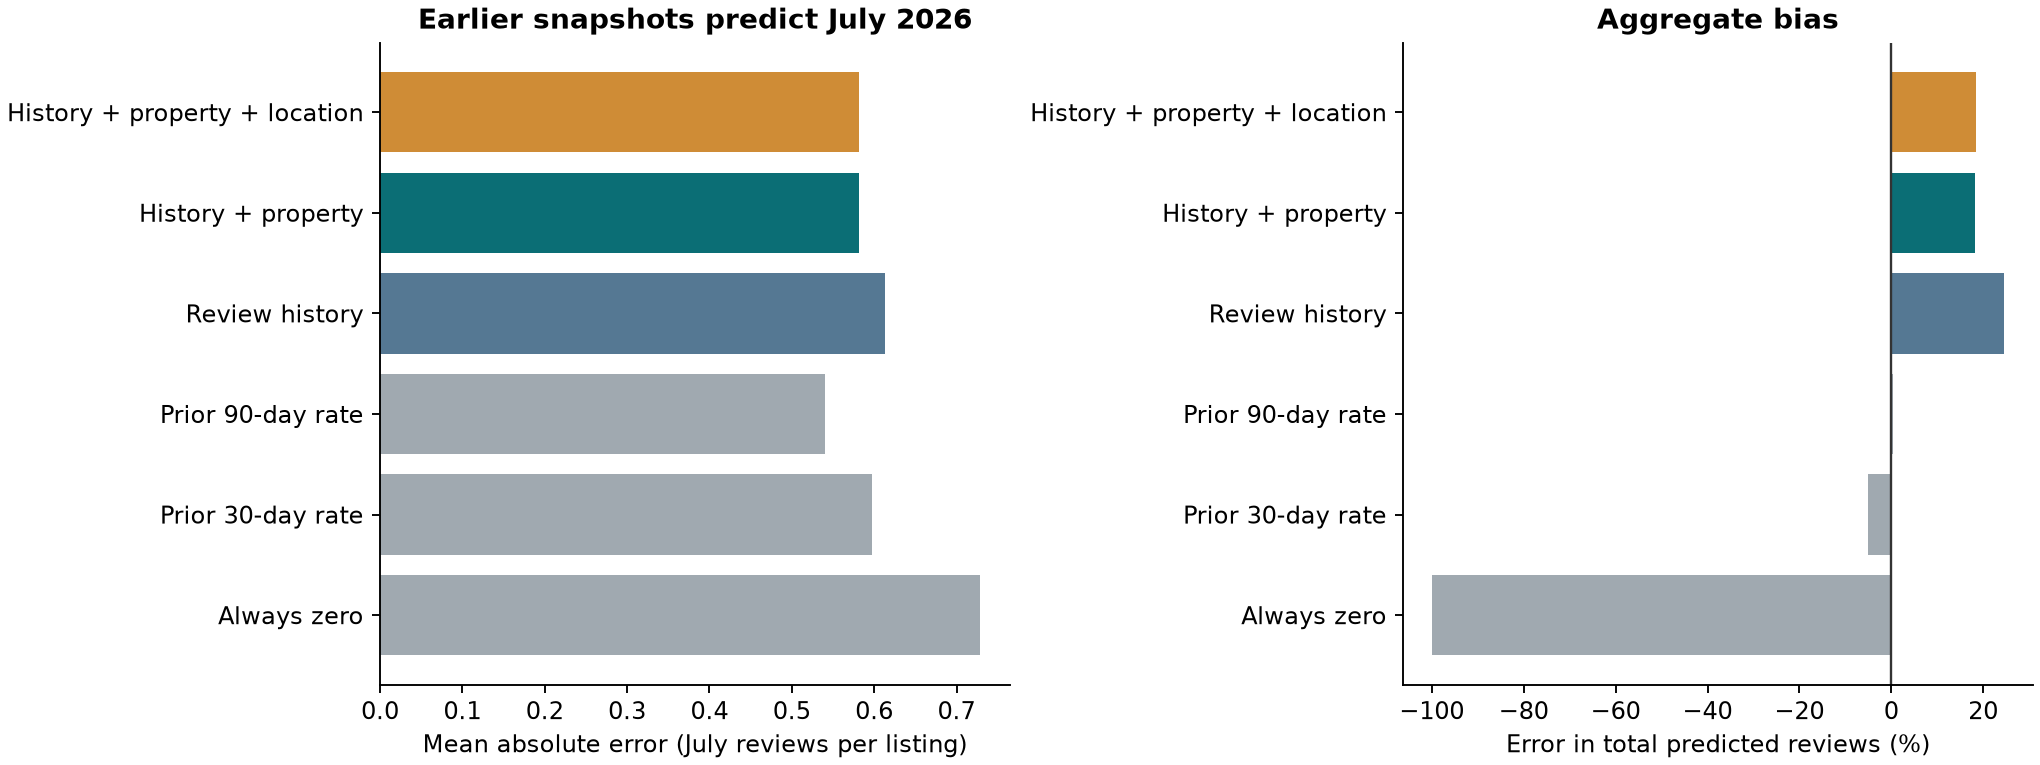

In [18]:
temporal_metrics = fit_temporal_models(temporal_panel)
temporal_figure(temporal_metrics)
display(temporal_metrics.round(3))
display(Image(filename=str(ROOT/'figures/temporal_review_models.png')))


## 9. Monthly, quarterly and annual revenue scenarios

Revenue requires an assumed opening plan and utilization rate because actual bookings are absent. The calculator uses a price benchmark and a seasonal review pattern only as scenario ingredients. It does not turn reviews into validated booking probabilities.

The example assumes ten open nights each month, three utilization levels and a constant nightly benchmark. Costs, financing and capital are unknown and remain `None`; consequently no personal ROI is reported. Edit the assumptions in the next cell to evaluate a conditional case. The annual night budget, if supplied, is an operating constraint over these twelve months, not a statement about rental law.


In [19]:
def seasonality(r, audit):
    end = pd.Period(audit["review_panel"]["last_complete_month"], freq="M")
    start = end - 11
    first = r.groupby("listing_id").date.min()
    cohort = first[first < start.start_time].index
    rr = r[r.listing_id.isin(cohort) & (r.date >= start.start_time) & (r.date < (end+1).start_time)]
    counts = rr.groupby(rr.date.dt.to_period("M")).size().reindex(pd.period_range(start, end, freq="M"), fill_value=0)
    per_day = counts.to_numpy() / np.array([m.days_in_month for m in counts.index])
    factor = per_day / (counts.sum() / sum(m.days_in_month for m in counts.index))
    s = pd.DataFrame({"period": counts.index.astype(str), "month": counts.index.month, "reviews": counts.to_numpy(),
                      "daily_review_factor": factor}).sort_values("month")
    s.to_csv(ROOT / "results/seasonality.csv", index=False)
    audit["seasonality"] = {"start": str(start), "end": str(end), "cohort_listings": len(cohort),
                            "interpretation": "One realized year of reviews among surviving established listings; scenario weight only."}
    # Plot uses full months only and labels snapshot-survivor population.
    recent = r[(r.date >= (end-47).start_time) & (r.date < (end+1).start_time)]
    monthly = recent.groupby(recent.date.dt.to_period("M")).size()
    monthly.to_csv(ROOT / "results/monthly_reviews.csv", header=["observed_reviews"])
    return s, monthly


def scenario_calculation(rate, factors, config):
    """Conditional scenario arithmetic; no estimation of actual occupancy or return."""
    if not np.isfinite(rate) or rate <= 0:
        raise ValueError("Nightly rate must be finite and positive.")
    if len(config["open_nights_by_month"]) != 12:
        raise ValueError("Provide twelve monthly opening-night values.")
    if any(not np.isfinite(v) or not 0 <= v <= 1 for v in config["occupancy_scenarios"].values()):
        raise ValueError("Occupancy assumptions must lie between zero and one.")
    if not np.isfinite(config["realised_price_multiplier"]) or config["realised_price_multiplier"] <= 0:
        raise ValueError("Realised price multiplier must be positive.")
    if config.get("variable_cost_rate") is not None and not 0 <= config["variable_cost_rate"] <= 1:
        raise ValueError("Variable-cost share must lie between zero and one.")
    for key in ["annual_booked_night_budget", "fixed_cost_per_month_eur", "financing_cash_per_month_eur", "initial_cash_investment_eur"]:
        if config.get(key) is not None and (not np.isfinite(config[key]) or config[key] < 0):
            raise ValueError(f"{key} must be non-negative or null.")
    start = pd.Period(config["start_month"], freq="M")
    periods = pd.period_range(start, periods=12, freq="M")
    rows = []
    for name, base_occupancy in config["occupancy_scenarios"].items():
        annual_remaining = config.get("annual_booked_night_budget")
        for i, period in enumerate(periods):
            open_nights = float(config["open_nights_by_month"][i])
            if not np.isfinite(open_nights) or not 0 <= open_nights <= period.days_in_month:
                raise ValueError(f"Open nights must fit within {period}.")
            factor = float(factors.loc[period.month])
            occupied = min(open_nights, open_nights * base_occupancy * factor)
            if annual_remaining is not None:
                occupied = min(occupied, max(0, annual_remaining))
                annual_remaining -= occupied
            gross = occupied * rate * config["realised_price_multiplier"]
            inputs = [config.get(k) for k in ["variable_cost_rate", "fixed_cost_per_month_eur", "financing_cash_per_month_eur"]]
            cash = None if any(x is None for x in inputs) else gross*(1-inputs[0])-inputs[1]-inputs[2]
            rows.append({"scenario": name, "month": str(period), "calendar_quarter": str(period.asfreq("Q")),
                         "nightly_rate_eur": rate, "open_nights": open_nights,
                         "assumed_base_occupancy": base_occupancy, "review_season_factor": factor,
                         "scenario_booked_nights": occupied, "gross_revenue_eur": gross,
                         "cash_flow_eur": cash})
    return pd.DataFrame(rows)


def scenarios(rate, s):
    config = json.loads((ROOT / "scenario_inputs.json").read_text())
    result = scenario_calculation(rate, s.set_index("month").daily_review_factor, config)
    result.to_csv(ROOT / "results/revenue_scenarios_monthly.csv", index=False)
    quarterly = result.groupby(["scenario", "calendar_quarter"])[["open_nights", "scenario_booked_nights", "gross_revenue_eur"]].sum()
    quarterly["months_in_period"] = result.groupby(["scenario", "calendar_quarter"]).size()
    quarterly.to_csv(ROOT / "results/revenue_scenarios_quarterly.csv")
    horizon = []
    for name, g in result.groupby("scenario", sort=False):
        for n in [1, 3, 12]:
            a = g.head(n)
            cash = a.cash_flow_eur.sum() if a.cash_flow_eur.notna().all() else None
            investment = config.get("initial_cash_investment_eur")
            roi = cash/investment if n == 12 and cash is not None and investment and investment > 0 else None
            horizon.append({"scenario": name, "horizon_months": n, "gross_revenue_eur": a.gross_revenue_eur.sum(),
                            "booked_nights": a.scenario_booked_nights.sum(), "cash_flow_eur": cash,
                            "annual_cash_return_fraction": roi})
    h = pd.DataFrame(horizon)
    h.to_csv(ROOT / "results/revenue_scenarios_horizons.csv", index=False)
    assert np.allclose(result.groupby("scenario").gross_revenue_eur.sum().sort_index(),
                       h[h.horizon_months == 12].set_index("scenario").gross_revenue_eur.sort_index())
    assert (result.scenario_booked_nights <= result.open_nights + 1e-9).all()
    return result, h


def plots(d, prices, reviews, s, monthly, scenario):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    axes[0].hist(d.price_eur, bins=np.arange(20, 1020, 20), color=COLORS[2])
    axes[0].set(title="Quoted nightly prices", xlabel="EUR per night", ylabel="Listings")
    g = d.groupby("neighbourhood_cleansed").price_eur.median().sort_values()
    axes[1].barh(g.index, g.values, color=COLORS[1])
    axes[1].tick_params(axis="y", labelsize=8)
    axes[1].set(title="Median quote by arrondissement", xlabel="EUR per night")
    fig.savefig(ROOT / "figures/prices.png", dpi=170); plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    labels = {"median_baseline": "Median baseline", "internal": "Property + quote", "location": "+ Location", "transit": "+ Transit"}
    for ax, protocol, title in zip(axes, ["host_holdout", "spatial_holdout"], ["Unseen hosts", "Unseen 1 km cells; shared hosts removed"]):
        p = prices[prices.protocol == protocol]
        ax.bar([labels[x] for x in p.model], p.mae_eur, color=COLORS)
        ax.tick_params(axis="x", rotation=20)
        ax.set(title=title, ylabel="Mean absolute error (EUR/night)")
    fig.savefig(ROOT / "figures/price_model_comparison.png", dpi=170); plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    axes[0].plot(monthly.index.to_timestamp(), monthly.values, color=COLORS[2])
    axes[0].set(title="Review history of snapshot survivors", ylabel="Observed reviews per month")
    axes[0].tick_params(axis="x", rotation=25)
    axes[1].bar([calendar.month_abbr[m] for m in s.month], s.daily_review_factor, color=COLORS[1])
    axes[1].axhline(1, color="#555", lw=1, ls="--")
    axes[1].set(title="Latest complete year's review pattern", ylabel="Daily review rate / annual daily rate")
    fig.savefig(ROOT / "figures/review_history.png", dpi=170); plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    for ax, eval_, title in zip(axes, ["rolling_one_month", "fixed_origin_three_months"], ["Rolling next-month review counts", "Three months from a single origin"]):
        p = reviews[reviews.evaluation == eval_]
        ax.barh([x.replace("_", " ") for x in p.model], p.mae_reviews, color=COLORS[:len(p)])
        ax.set(title=title, xlabel="Mean absolute error (reviews per listing)")
    fig.savefig(ROOT / "figures/review_model_comparison.png", dpi=170); plt.close(fig)
    fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
    for (name, p), color in zip(scenario.groupby("scenario", sort=False), [COLORS[1], COLORS[2], COLORS[3]]):
        ax.plot(p.month, p.gross_revenue_eur, "o-", color=color, label=name)
    ax.set(title="Illustrative gross revenue scenarios", ylabel="EUR per month", xlabel="Scenario month")
    ax.tick_params(axis="x", rotation=35)
    ax.legend(frameon=False)
    fig.savefig(ROOT / "figures/revenue_scenarios.png", dpi=170); plt.close(fig)

In [20]:
assumptions = {'description': "Illustrative assumptions only. These are not the user's operating plan and are not fitted occupancy forecasts. Replace before personalized use.", 'start_month': '2026-12', 'open_nights_by_month': [10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10], 'occupancy_scenarios': {'Lower utilisation': 0.35, 'Central utilisation': 0.5, 'Higher utilisation': 0.65}, 'realised_price_multiplier': 1.0, 'annual_booked_night_budget': None, 'variable_cost_rate': None, 'fixed_cost_per_month_eur': None, 'financing_cash_per_month_eur': None, 'initial_cash_investment_eur': None, 'capacity_note': 'Open nights are an operating assumption, not a statement of legal eligibility or an applicable rental limit.', 'seasonality_note': "The latest complete year's daily review pattern weights monthly occupancy. It is a scenario assumption, not calibrated occupancy seasonality."}

if REBUILD_INPUTS:
    season_table, review_history = seasonality(latest_reviews, audit)
else:
    season_table = pd.read_csv(ROOT/'results/seasonality.csv')
    raw_history = pd.read_csv(ROOT/'results/monthly_reviews.csv', index_col=0)
    review_history = raw_history.iloc[:, 0]
    review_history.index = pd.PeriodIndex(review_history.index, freq='M')
monthly_scenarios = scenario_calculation(example_rate, season_table.set_index('month').daily_review_factor, assumptions)
monthly_scenarios.to_csv(ROOT/'results/notebook_monthly_scenarios.csv', index=False)
display(monthly_scenarios.head(12).round(2))
display(monthly_scenarios.groupby('scenario')[['gross_revenue_eur','scenario_booked_nights']].sum().round(2))


,scenario,month,calendar_quarter,nightly_rate_eur,open_nights,assumed_base_occupancy,review_season_factor,scenario_booked_nights,gross_revenue_eur,cash_flow_eur
0,Lower utilisation,2026-12,2026Q4,181.87,10.0,0.35,0.80,2.80,509.75,None
1,Lower utilisation,2027-01,2027Q1,181.87,10.0,0.35,0.79,2.75,499.89,None
2,Lower utilisation,2027-02,2027Q1,181.87,10.0,0.35,0.80,2.80,508.40,None
3,Lower utilisation,2027-03,2027Q1,181.87,10.0,0.35,0.88,3.08,560.44,None
4,Lower utilisation,2027-04,2027Q2,181.87,10.0,0.35,1.16,4.07,740.45,None
5,Lower utilisation,2027-05,2027Q2,181.87,10.0,0.35,1.23,4.29,780.56,None
6,Lower utilisation,2027-06,2027Q2,181.87,10.0,0.35,1.31,4.60,835.92,None
7,Lower utilisation,2027-07,2027Q3,181.87,10.0,0.35,1.07,3.75,682.71,None
8,Lower utilisation,2027-08,2027Q3,181.87,10.0,0.35,0.77,2.71,491.95,None
9,Lower utilisation,2027-09,2027Q3,181.87,10.0,0.35,1.14,3.98,724.61,None


,gross_revenue_eur,scenario_booked_nights
scenario,,
Central utilisation,10908.67,59.98
Higher utilisation,14181.26,77.98
Lower utilisation,7636.07,41.99


Calendar-quarter totals; months_in_period identifies partial first/last quarters:


months_in_period  gross_revenue_eur  \
scenario            calendar_quarter                                        
Lower utilisation   2026Q4                           1             509.75   
                    2027Q1                           3            1568.73   
                    2027Q2                           3            2356.93   
                    2027Q3                           3            1899.27   
                    2027Q4                           2            1301.39   
Central utilisation 2026Q4                           1             728.21   
                    2027Q1                           3            2241.05   
                    2027Q2                           3            3367.04   
                    2027Q3                           3            2713.24   
                    2027Q4                           2            1859.13   
Higher utilisation  2026Q4                           1             946.67   
                    2027Q1                           3            2913.36   
                    2027Q2                           3            4377.15   
                    2027Q3                           3            3527.21   
                    2027Q4                           2            2416.87   

                                      open_nights  scenario_booked_nights  
scenario            calendar_quarter                                       
Lower utilisation   2026Q4                   10.0                    2.80  
                    2027Q1                   30.0                    8.63  
                    2027Q2                   30.0                   12.96  
                    2027Q3                   30.0                   10.44  
                    2027Q4                   20.0                    7.16  
Central utilisation 2026Q4                   10.0                    4.00  
                    2027Q1                   30.0                   12.32  
                    2027Q2                   30.0                   18.51  
                    2027Q3                   30.0                   14.92  
                    2027Q4                   20.0                   10.22  
Higher utilisation  2026Q4                   10.0                    5.21  
                    2027Q1                   30.0                   16.02  
                    2027Q2                   30.0                   24.07  
                    2027Q3                   30.0                   19.39  
                    2027Q4                   20.0                   13.29

Cumulative totals over the first 1, 3 and 12 scenario months:


,scenario,months,gross_revenue_eur,cash_flow_eur,annual_cash_return
0,Lower utilisation,1,509.75,NaN,NaN
1,Lower utilisation,3,1518.04,NaN,NaN
2,Lower utilisation,12,7636.07,NaN,NaN
3,Central utilisation,1,728.21,NaN,NaN
4,Central utilisation,3,2168.63,NaN,NaN
5,Central utilisation,12,10908.67,NaN,NaN
6,Higher utilisation,1,946.67,NaN,NaN
7,Higher utilisation,3,2819.22,NaN,NaN
8,Higher utilisation,12,14181.26,NaN,NaN


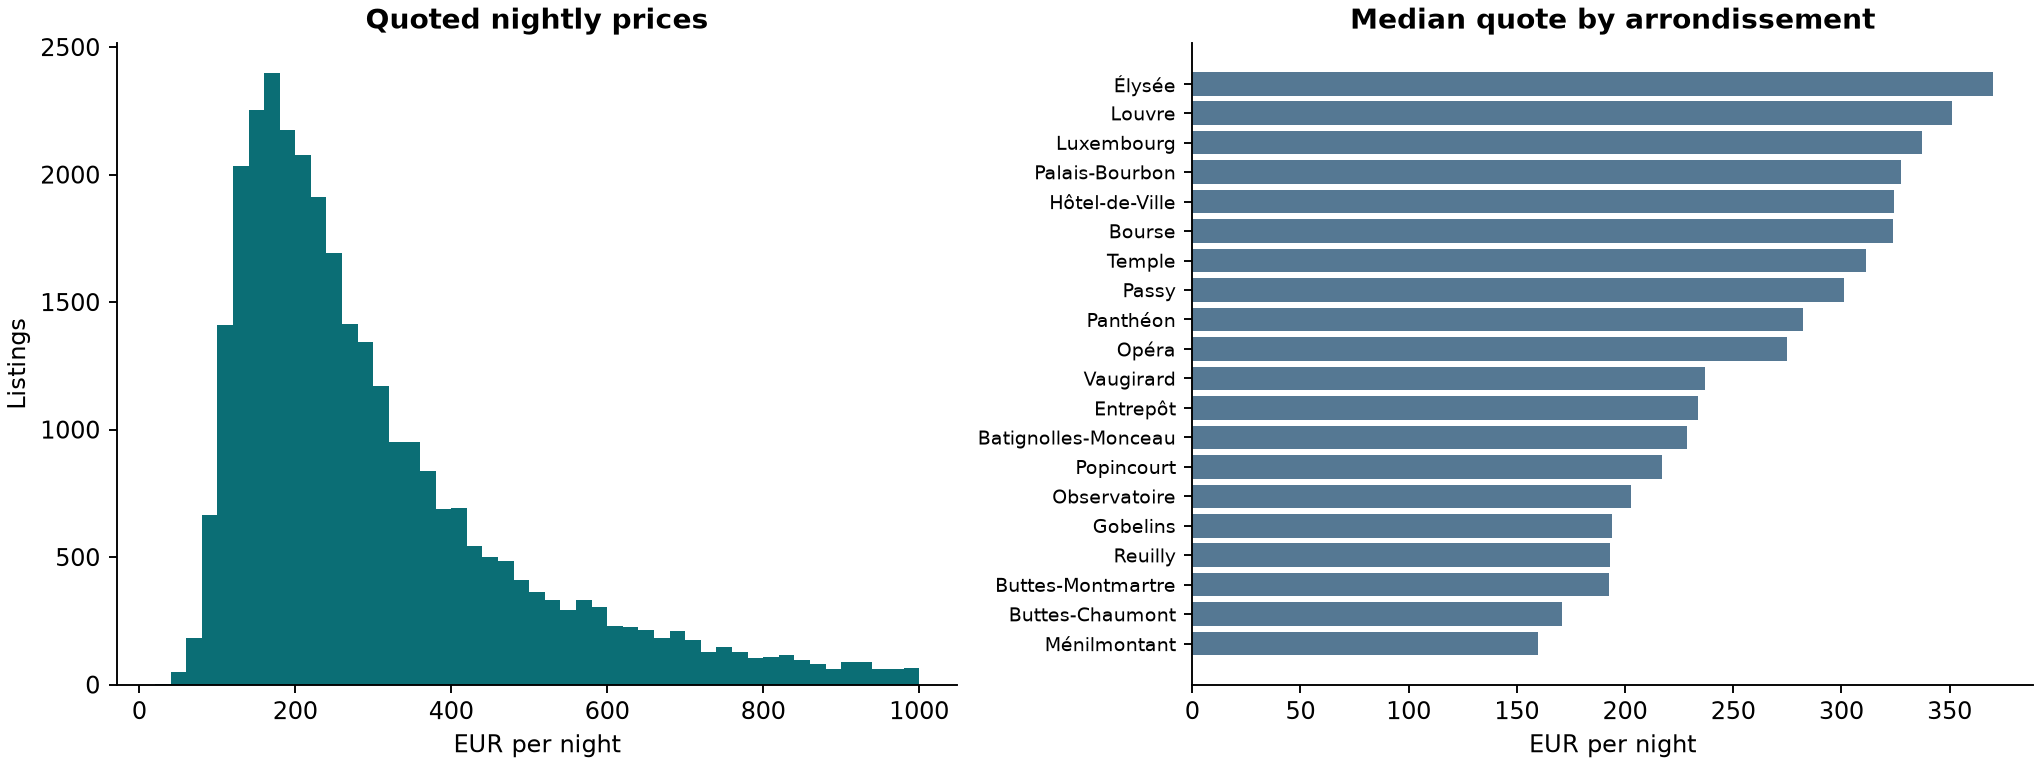

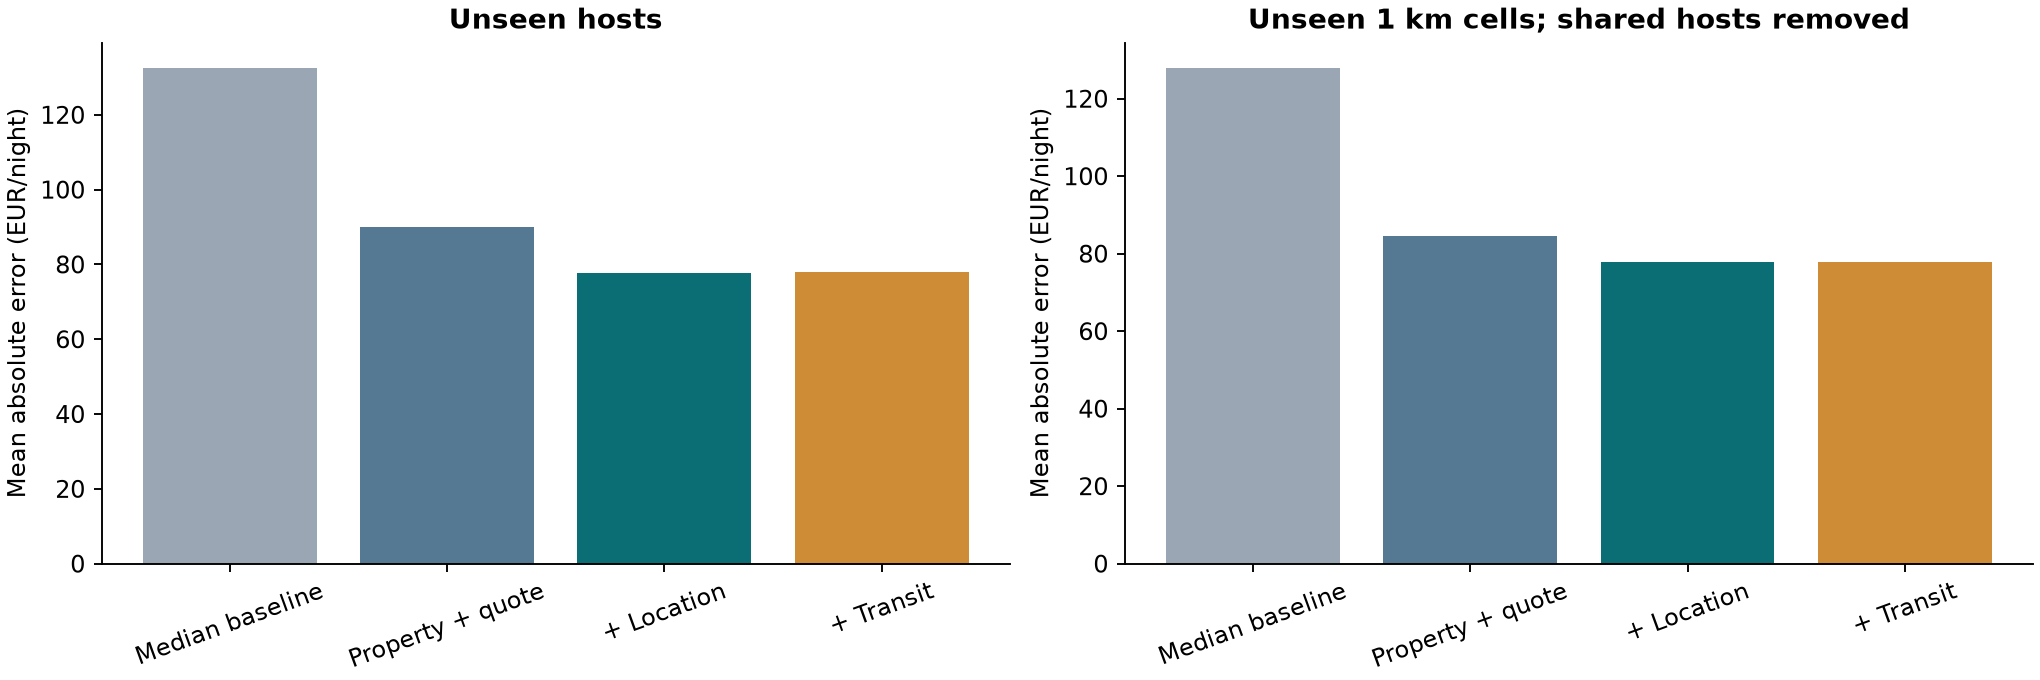

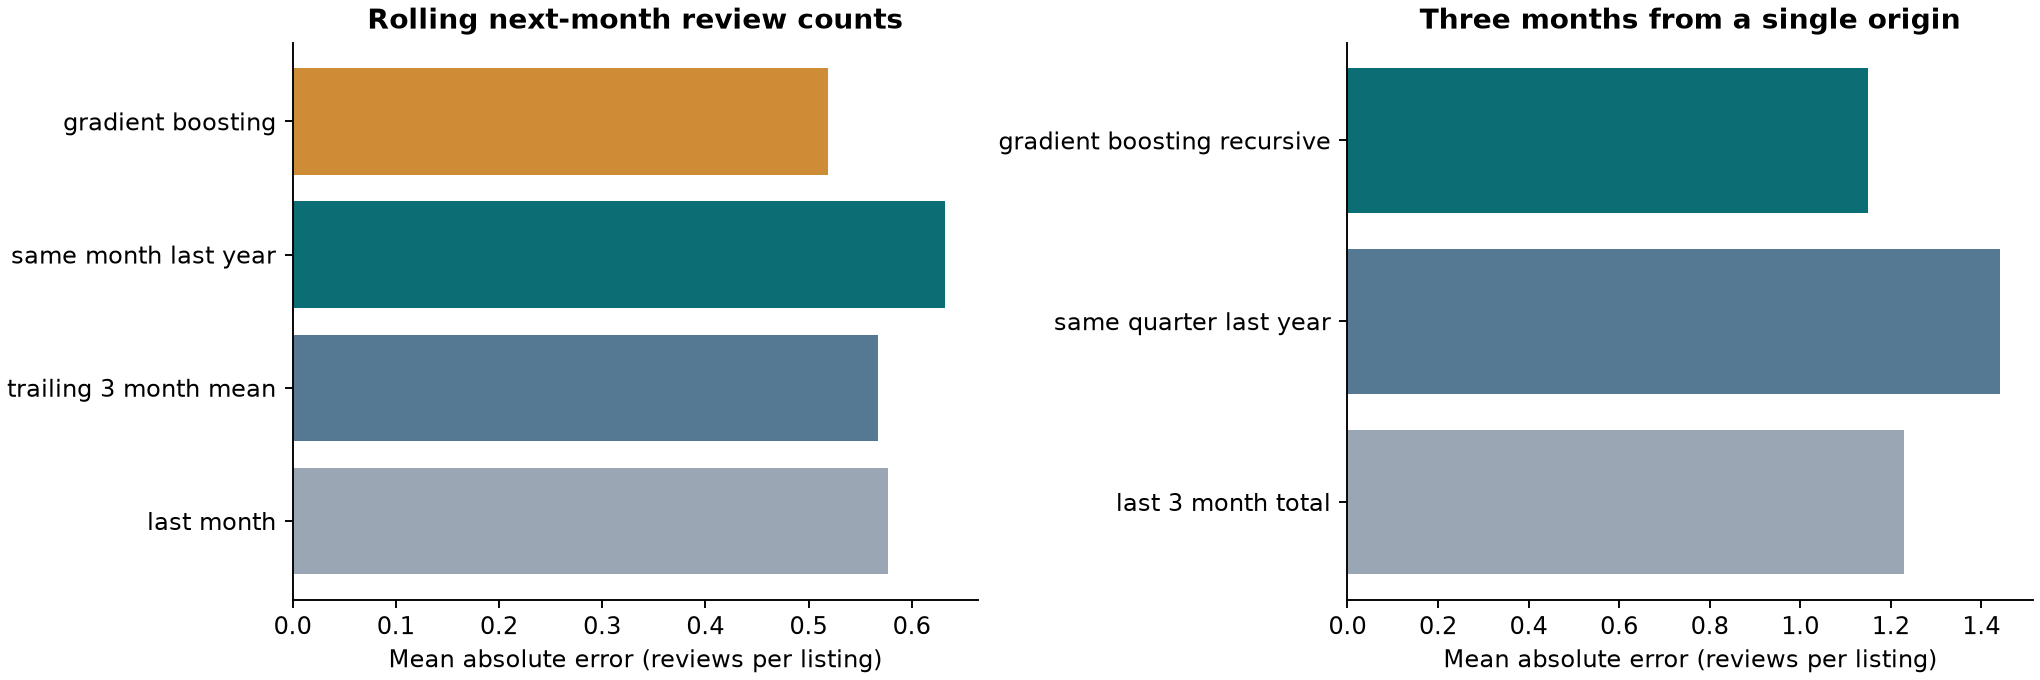

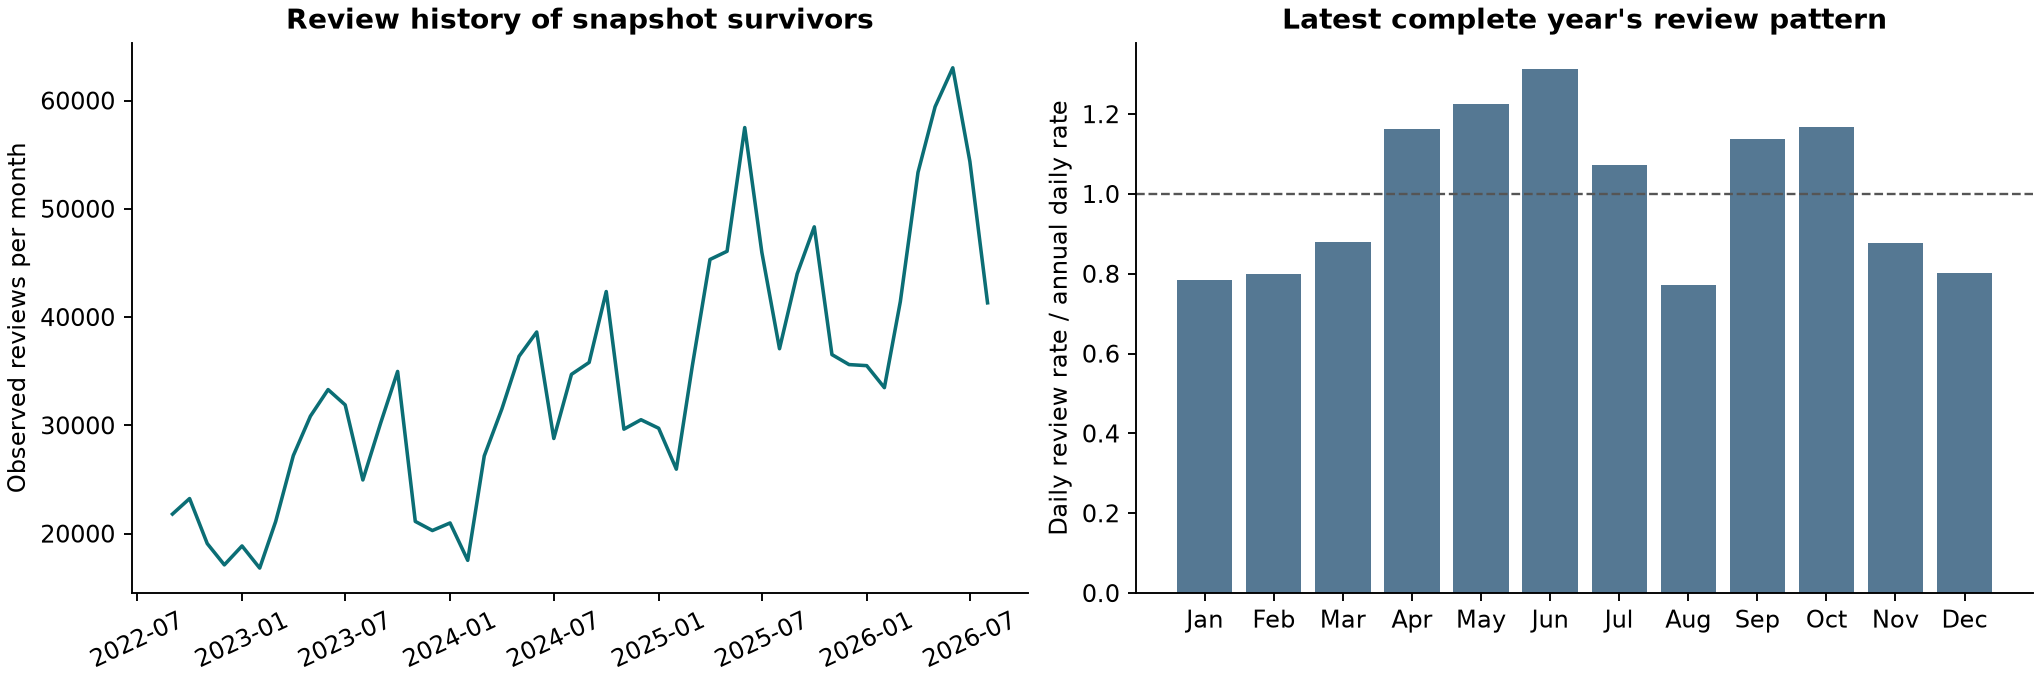

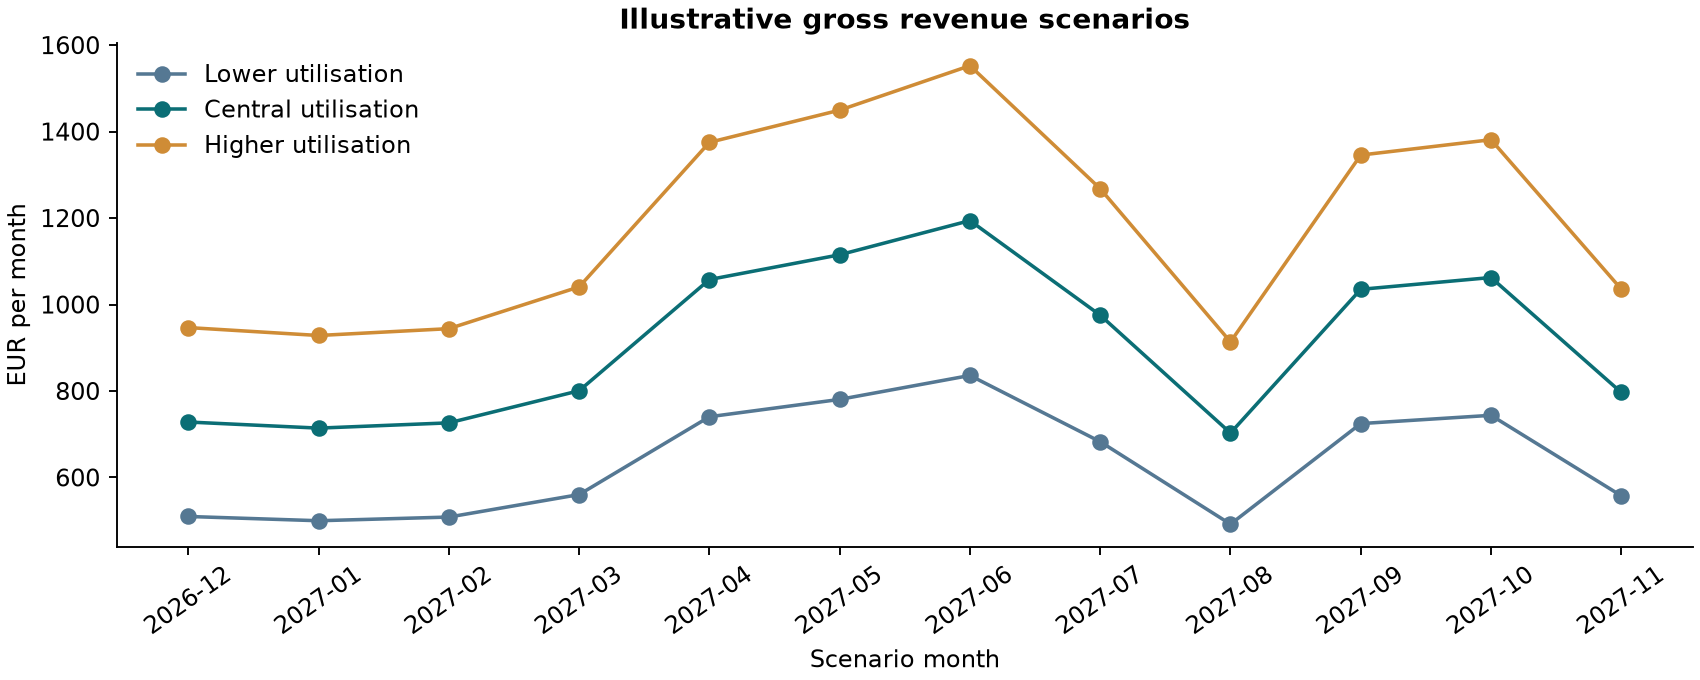

In [21]:
# Sum corresponding months; do not multiply one month's revenue by 3 or 12.
quarterly_scenarios = monthly_scenarios.groupby(['scenario','calendar_quarter'], sort=False).agg(
    months_in_period=('month','size'), gross_revenue_eur=('gross_revenue_eur','sum'),
    open_nights=('open_nights','sum'), scenario_booked_nights=('scenario_booked_nights','sum'))
quarterly_scenarios.to_csv(ROOT/'results/notebook_quarterly_scenarios.csv')
print('Calendar-quarter totals; months_in_period identifies partial first/last quarters:')
display(quarterly_scenarios.round(2))
horizons = []
for name, group in monthly_scenarios.groupby('scenario', sort=False):
    for n in [1, 3, 12]:
        selected = group.head(n)
        cash = selected.cash_flow_eur.sum() if selected.cash_flow_eur.notna().all() else np.nan
        capital = assumptions.get('initial_cash_investment_eur')
        roi = cash/capital if n == 12 and capital and capital > 0 else np.nan
        horizons.append({'scenario':name, 'months':n, 'gross_revenue_eur':selected.gross_revenue_eur.sum(),
                         'cash_flow_eur':cash, 'annual_cash_return':roi})
horizon_table = pd.DataFrame(horizons)
horizon_table.to_csv(ROOT/'results/notebook_scenario_horizons.csv', index=False)
print('Cumulative totals over the first 1, 3 and 12 scenario months:')
display(horizon_table.round(2))
plots(price_data, price_metrics_table, review_metrics_table, season_table, review_history, monthly_scenarios)
for filename in ['prices.png','price_model_comparison.png','review_model_comparison.png','review_history.png','revenue_scenarios.png']:
    display(Image(filename=str(ROOT/'figures'/filename)))


## 10. Independent checks and interpretation

These checks test temporal lag alignment, the distinction between missing and zero outcomes, saved prediction metrics and the scenario calculation. The synthetic EUR 100 case checks arithmetic only; it is not an empirical property forecast.


In [22]:
ordered = review_inputs[0].sort_values(['listing_id','month'])
for lag in [1,2,3,6,12]:
    previous = ordered.groupby('listing_id').target.shift(lag)
    present = previous.notna()
    assert np.allclose(ordered.loc[present, f'lag_{lag}'], previous[present])
assert not temporal_panel.duplicated(['id','target_month']).any()
assert temporal_panel.loc[~temporal_panel.followup_observed,'target'].isna().all()
for protocol in ['host_holdout','spatial_holdout']:
    predicted = pd.read_csv(ROOT/f'results/price_predictions_{protocol}.csv')
    for model in ['median_baseline','internal','location','transit']:
        stored = price_metrics_table[(price_metrics_table.protocol==protocol)&(price_metrics_table.model==model)].mae_eur.iloc[0]
        assert np.isclose(np.abs(predicted.actual_price_eur-predicted[model]).mean(), stored)
example_inputs = dict(assumptions)
example_inputs.update(open_nights_by_month=[10]*12, occupancy_scenarios={'test':.5}, realised_price_multiplier=1.,
                      annual_booked_night_budget=None, variable_cost_rate=.2, fixed_cost_per_month_eur=100., financing_cash_per_month_eur=20.)
flat_season = pd.Series(1., index=range(1,13))
synthetic = scenario_calculation(100., flat_season, example_inputs)
assert np.allclose(synthetic.gross_revenue_eur, 500.)
assert np.allclose(synthetic.cash_flow_eur, 280.)
example_inputs['annual_booked_night_budget'] = 7
assert np.isclose(scenario_calculation(100.,flat_season,example_inputs).scenario_booked_nights.sum(),7.)
assert (monthly_scenarios.scenario_booked_nights <= monthly_scenarios.open_nights).all()
assert np.allclose(quarterly_scenarios.groupby('scenario').gross_revenue_eur.sum().sort_index(),
                   monthly_scenarios.groupby('scenario').gross_revenue_eur.sum().sort_index())
for name, group in monthly_scenarios.groupby('scenario', sort=False):
    for n in [1,3,12]:
        stored = horizon_table[(horizon_table.scenario==name)&(horizon_table.months==n)].gross_revenue_eur.iloc[0]
        assert np.isclose(stored, group.head(n).gross_revenue_eur.sum())
audit['price_deployment_feature_set'] = chosen_price_features
audit['package_versions'] = {'pandas':pd.__version__,'numpy':np.__version__,'scikit-learn':sklearn.__version__}
dump(ROOT/'results/data_audit.json',audit)
print('All notebook checks passed.')


All notebook checks passed.


## Conclusions and remaining data

- Report price and review errors as different tasks. Neither is a real-revenue score.
- Read the location and transit comparisons directly from their held-out errors; external features are not guaranteed to help.
- In the earlier-snapshot July test, the 90-day review-rate baseline has MAE 0.5403 and total bias +0.26%, versus MAE 0.5820 and bias +18.51% for boosting with history, property and location. The simpler baseline wins on MAE; boosting has lower RMSE. The earlier rolling-cohort gain does not transfer automatically.
- Historical snapshots improve input timing, but missing follow-up and uneven snapshot coverage still limit inference.
- Actual booking/revenue records are needed for earnings validation. Costs, opening plans, financing and cash invested are needed for a personal return calculation.
- A longer sequence of complete target months is needed to validate seasonality and multi-month forecasts. Weather should be known at the forecast origin; neither weather nor neighborhood-income data is fitted in this version.

### Sources

- [Inside Airbnb downloads and archive list](https://insideairbnb.com/get-the-data/).
- [Inside Airbnb data assumptions](https://insideairbnb.com/data-assumptions/) and [data dictionary](https://docs.google.com/spreadsheets/d/1iWCNJcSutYqpULSQHlNyGInUvHg2BoUGoNRIGa6Szc4/edit).
- [Official Île-de-France transport stations](https://data.iledefrance-mobilites.fr/explore/dataset/emplacement-des-gares-idf-data-generalisee/).

Original file URLs and hashes are retained in the audit manifests. See REPORT.html and DATA_NEEDED.md for the written interpretation and prioritized extensions.
